# SF iNext


Use pyforest_env virtual environment, projection seems to work better there and has less issues 

This Code has been updated with 2025 SF ebird data (Jan 2010 - Dec 2025)

# Import and Set Environments

In [2]:
#%pip install seaborn
#%pip install statsmodels
#%pip install shapely
#%pip install duckdb
# Import libraries
import os

# Set PROJ_LIB BEFORE importing geopandas
os.environ['PROJ_LIB'] = r'C:\Users\einna\anaconda3\envs\sf_env\Library\share\proj'



import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkb, wkt
import geopandas as gpd
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import warnings




# Connect and Load Duckdb

In [3]:


# ============================================================================
# 1. IMPORT DATA
# ============================================================================
# Connect to DuckDB
con = duckdb.connect()

# Load non-null parquets into DuckDB
con.execute("CREATE OR REPLACE TABLE ebird_sf AS SELECT * FROM read_parquet('../data/output/ebird_hex_parquets_april2026/ebird_holc_joined_4_26_26.parquet')")

# Check the structure of the data
str_result = con.execute("SELECT column_name, data_type FROM information_schema.columns WHERE table_name = 'ebird_sf'").fetchall()
print(str_result)

# Load spatial extension for DuckDB
con.execute("INSTALL spatial; LOAD spatial;")



[('hex_id', 'VARCHAR'), ('scientific_name', 'VARCHAR'), ('total_max_observations', 'DOUBLE'), ('num_checklists', 'BIGINT'), ('num_observation_days', 'BIGINT'), ('first_observed', 'DATE'), ('last_observed', 'DATE'), ('num_years_observed', 'BIGINT'), ('hexagon_geom', 'GEOMETRY(\'{"$schema":"https://proj.org/schemas/v0.5/projjson.schema.json","type":"ProjectedCRS","name":"WGS 84 / UTM zone 10N","base_crs":{"name":"WGS 84","datum_ensemble":{"name":"World Geodetic System 1984 ensemble","members":[{"name":"World Geodetic System 1984 (Transit)","id":{"authority":"EPSG","code":1166}},{"name":"World Geodetic System 1984 (G730)","id":{"authority":"EPSG","code":1152}},{"name":"World Geodetic System 1984 (G873)","id":{"authority":"EPSG","code":1153}},{"name":"World Geodetic System 1984 (G1150)","id":{"authority":"EPSG","code":1154}},{"name":"World Geodetic System 1984 (G1674)","id":{"authority":"EPSG","code":1155}},{"name":"World Geodetic System 1984 (G1762)","id":{"authority":"EPSG","code":1156}}

In [4]:
query = """
    SELECT 
        hex_id,
        SUM(num_checklists) as num_checklists
    FROM ebird_sf
    GROUP BY hex_id
"""

df = con.execute(query).df()

# Find which hexagons have max/min
max_hex = df.loc[df['num_checklists'].idxmax()]
min_hex = df.loc[df['num_checklists'].idxmin()]

print(f"Maximum: {max_hex['num_checklists']} checklists in hexagon {max_hex['hex_id']}")
print(f"Minimum: {min_hex['num_checklists']} checklists in hexagon {min_hex['hex_id']}")
print(f"Average: {df['num_checklists'].mean():.2f} checklists")

# Extract grade from hex_id (last character)
df['grade'] = df['hex_id'].str[-1]


sampling_by_grade = (
    df.groupby('grade')
    .agg(
        mean_checklists=('num_checklists', 'mean'),
        min_checklists=('num_checklists', 'min')
    )
    .reset_index()
)

print(sampling_by_grade)

Maximum: 118260.0 checklists in hexagon 4110_D
Minimum: 80.0 checklists in hexagon 3031_C
Average: 1758.59 checklists
  grade  mean_checklists  min_checklists
0     A      1015.257143           126.0
1     B       899.608491            88.0
2     C      2499.361789            80.0
3     D      1862.558233            98.0


In [10]:
query = """
    SELECT 
        scientific_name, 
        hex_id,
        SUM(CAST(total_max_observations AS INTEGER)) as max_observations,
        ST_AsText(hexagon_geom) as geometry_wkt
    FROM ebird_sf
    WHERE total_max_observations IS NOT NULL
    GROUP BY scientific_name, hex_id, hexagon_geom
"""

df = con.execute(query).df()

# Convert WKT to geometry
ebird_HOLC_agg = gpd.GeoDataFrame(
    df,
    geometry=gpd.GeoSeries.from_wkt(df['geometry_wkt']),
    crs="EPSG:32610"
).drop(columns=['geometry_wkt'])

print(f"Total rows: {len(ebird_HOLC_agg)}")
print(f"CRS: {ebird_HOLC_agg.crs}")
print(f"Bounds: {ebird_HOLC_agg.total_bounds}")

Total rows: 155581
CRS: EPSG:32610
Bounds: [ 543245.9912916  4173580.56090403  555845.9912916  4184434.74596479]


In [ ]:
# Find which hexagons have max/min
max_hex = df.loc[df['num_checklists'].idxmax()]
min_hex = df.loc[df['num_checklists'].idxmin()]

print(f"Maximum: {max_hex['num_checklists']} checklists in hexagon {max_hex['hex_id']}")
print(f"Minimum: {min_hex['num_checklists']} checklists in hexagon {min_hex['hex_id']}")
print(f"Average: {df['num_checklists'].mean():.2f} checklists")

In [11]:
import folium

# Explore the GeoDataFrame
bbox_GER = gpd.read_file("../data/dependent_var/redlining/SF_HOLC_cleaned.geojson")

# Transform to CRS 
bbox_GER = bbox_GER.to_crs(epsg=32610)


# Create base map from HOLC boundaries
m = bbox_GER.explore(
    column='grade',
    categorical=True,
    tiles='CartoDB positron',
    cmap=['#9FE2BF', '#6495ED', '#FFBF00', '#DE3163'],
    legend=True,
    name='HOLC Boundaries',  # Name for layer control
    style_kwds={'fillOpacity': 0.3, 'weight': 2, 'color': 'black'}
)

# Add eBird hexagons as overlay layer
ebird_HOLC_agg.sample(1000, random_state=42).explore(
    m=m,  # Add to existing map
    tooltip=['hex_id', 'scientific_name', 'max_observations'],
    legend=False,  # Don't duplicate legend
    name='eBird Hexagons',  # Name for layer control
    style_kwds={'fillOpacity': 0.6, 'weight': 0.5}
)

# Add layer control
folium.LayerControl().add_to(m)


m

In [12]:
#print out the first few rows of the GeoDataFrame to check the geometry column
print(ebird_HOLC_agg.head())
# Extract grade from hex_id (last character)
ebird_HOLC_agg= ebird_HOLC_agg.copy()
ebird_HOLC_agg['grade'] = ebird_HOLC_agg['hex_id'].str[-1]

# Export intermediate step
#output_path = "D:/Chapter1_LA_redlining/ebird_HOLC_agg.geojson"
#ebird_HOLC_agg.to_file(output_path)

print(f"Unique grades: {ebird_HOLC_agg['grade'].unique()}")
print(f"Unique grades: {ebird_HOLC_agg['hex_id'].unique()}")

print(f"Rows after filtering: {len(ebird_HOLC_agg)}")

#we'll need to get rid of the hexagons that didn't have a grde because it was designated null (commericial) in the original shapeifle.
ebird_HOLC_agg

          scientific_name  hex_id  max_observations  \
0           Aythya marila  3458_C               0.0   
1  Arenaria melanocephala  1427_B               0.0   
2       Icterus bullockii  2301_B               0.0   
3     Meleagris gallopavo  1908_D               0.0   
4       Falco columbarius  2751_C               0.0   

                                            geometry  
0  POLYGON ((551145.991 4183713.058, 551095.991 4...  
1  POLYGON ((546995.991 4175485.817, 546945.991 4...  
2  POLYGON ((548945.991 4179729.341, 548895.991 4...  
3  POLYGON ((547995.991 4174446.586, 547945.991 4...  
4  POLYGON ((549795.991 4178430.303, 549745.991 4...  
Unique grades: <ArrowStringArray>
['C', 'B', 'D', 'A']
Length: 4, dtype: str
Unique grades: <ArrowStringArray>
['3458_C', '1427_B', '2301_B', '1908_D', '2751_C', '3799_D', '3420_D',
  '261_B', '3592_D', '3319_D',
 ...
 '3960_D', '1522_A', '2287_C', '3209_D',  '335_B', '2311_C', '3990_D',
 '2655_C',  '924_B', '1169_C']
Length: 742, dtype:

,scientific_name,hex_id,max_observations,geometry,grade
0,Aythya marila,3458_C,0.0,"POLYGON ((551145.991 4183713.058, 551095.991 4...",C
1,Arenaria melanocephala,1427_B,0.0,"POLYGON ((546995.991 4175485.817, 546945.991 4...",B
2,Icterus bullockii,2301_B,0.0,"POLYGON ((548945.991 4179729.341, 548895.991 4...",B
3,Meleagris gallopavo,1908_D,0.0,"POLYGON ((547995.991 4174446.586, 547945.991 4...",D
4,Falco columbarius,2751_C,0.0,"POLYGON ((549795.991 4178430.303, 549745.991 4...",C
...,...,...,...,...,...
155576,Porzana carolina,2706_B,0.0,"POLYGON ((549745.991 4173840.369, 549695.991 4...",B
155577,Tyto furcata,3713_D,0.0,"POLYGON ((551795.991 4177910.688, 551745.991 4...",D
155578,Branta hutchinsii,2461_C,0.0,"POLYGON ((549245.991 4178343.701, 549195.991 4...",C
155579,Bubo virginianus,3458_C,0.0,"POLYGON ((551145.991 4183713.058, 551095.991 4...",C


# Processing Data

In [13]:

# ============================================================================
# 2. FILTER DATA (remove _nan and filter for 2+ species)
# ============================================================================

# Remove rows where hex_id contains "_nan"
filtered_data = ebird_HOLC_agg[~ebird_HOLC_agg['hex_id'].str.contains("_nan", na=False)]
print(f"Rows after filtering: {len(filtered_data)}")


# Filter for hexagons with 2+ species with more than 1 observation
ebird_species_filtered = (
    filtered_data[filtered_data['max_observations'] > 1]
    .groupby('hex_id')
    .filter(lambda x: x['scientific_name'].nunique() >= 2)
)


print(f"Rows after filtering: {len(ebird_species_filtered)}")


Rows after filtering: 155581
Rows after filtering: 4125


In [14]:
# ============================================================================
# 4. Select only 250 hexagons from each other 
# ============================================================================


from tqdm import tqdm

def select_spaced_hexagons_simple(gdf, min_distance=250):
    """
    Keep hexagons that are at least min_distance apart
    """
    print(f"Starting with {len(gdf)} hexagons")
    
    # Get centroids
    gdf = gdf.copy()
    centroids = gdf.geometry.centroid.values
    indices = gdf.index.tolist()
    
    # List to store selected indices
    selected_indices = []
    selected_centroids = []
    
    # Go through each hexagon
    for i in tqdm(range(len(gdf)), desc="Selecting hexagons"):
        current_centroid = centroids[i]
        
        # Check if far enough from all selected
        keep = True
        for selected_centroid in selected_centroids:
            if current_centroid.distance(selected_centroid) < min_distance:
                keep = False
                break
        
        # Keep it if far enough
        if keep:
            selected_indices.append(indices[i])
            selected_centroids.append(current_centroid)
    
    # Return selected hexagons
    result = gdf.loc[selected_indices]
    
    print(f"\nKept {len(result)} of {len(gdf)} hexagons ({len(result)/len(gdf)*100:.1f}%)")
    
    return result


# Get one representative row per hexagon for spatial filtering
hex_representatives = (ebird_species_filtered
                       .groupby('hex_id', as_index=False)
                       .first()[['hex_id', 'grade', 'geometry']])

print(f"Starting with {len(hex_representatives)} unique hexagons")

# Apply spatial filtering
selected_hexagons = select_spaced_hexagons_simple(
    hex_representatives, 
    min_distance=250
)

print(f"Selected {len(selected_hexagons)} hexagons")

# Keep all species data for selected hexagons
ebird_filtered_final = ebird_species_filtered.merge(
    selected_hexagons[['hex_id']], 
    on='hex_id', 
    how='inner'
)

print(f"\nFinal dataset:")
print(f"  Rows: {len(ebird_filtered_final)}")
print(f"  Hexagons: {ebird_filtered_final['hex_id'].nunique()}")
print(f"  Species: {ebird_filtered_final['scientific_name'].nunique()}")
print(f"  Avg species per hex: {len(ebird_filtered_final) / ebird_filtered_final['hex_id'].nunique():.1f}")

# Use it


Starting with 435 unique hexagons
Starting with 435 hexagons


Selecting hexagons: 100%|██████████| 435/435 [00:00<00:00, 1850.31it/s]


Kept 253 of 435 hexagons (58.2%)
Selected 253 hexagons

Final dataset:
  Rows: 2423
  Hexagons: 253
  Species: 169
  Avg species per hex: 9.6


<Axes: >

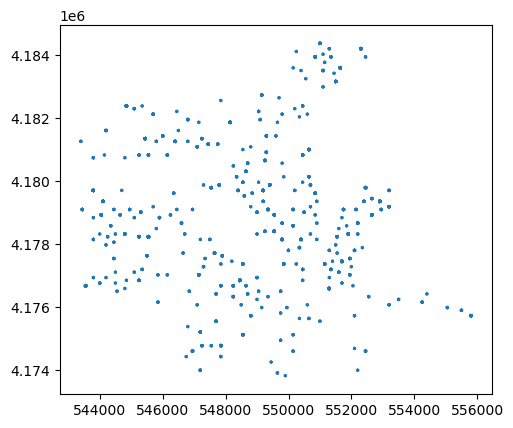

In [15]:
ebird_filtered_final.plot()

/tmp/ipykernel_1314075/3253333011.py:36: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  selected_hexagons.plot(


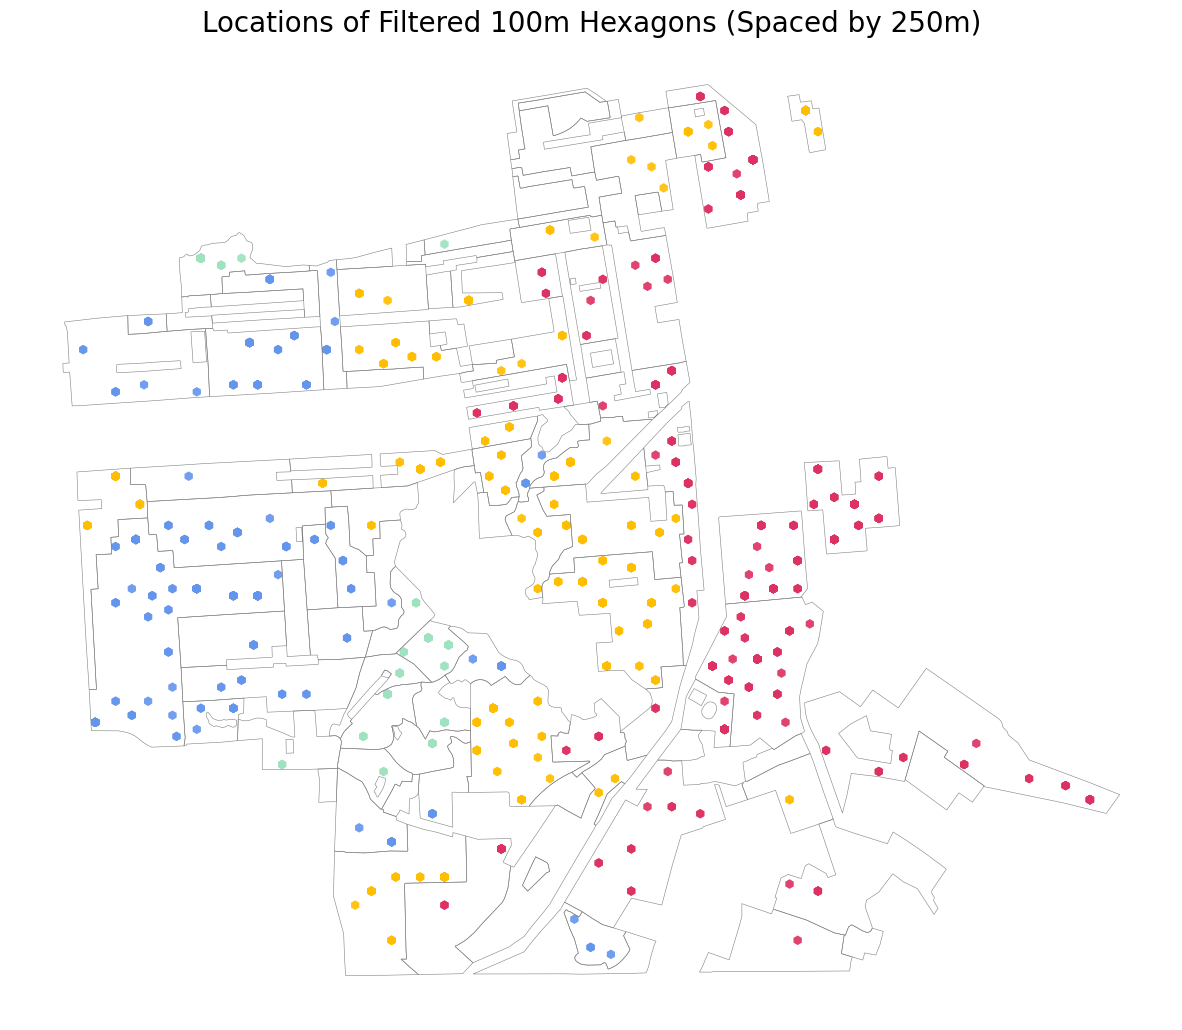

In [16]:

# ============================================================================
# 5. LOAD AND PREPARE HOLC BASEMAP
# ============================================================================

bbox_GER = gpd.read_file("../data/dependent_var/redlining/SF_HOLC_cleaned.geojson")

# Transform both to same CRS
selected_hexagons = ebird_filtered_final.to_crs(epsg=32610)
bbox_GER = bbox_GER.to_crs(epsg=32610)


# Extract grade from hex_id (last character)
selected_hexagons= selected_hexagons.copy()
selected_hexagons['grade'] = selected_hexagons['hex_id'].str[-1]


# Filter HOLC data
bbox_GER_filter = bbox_GER[bbox_GER['grade'].notna()]

# ============================================================================
# 6. VISUALIZE WITH MATPLOTLIB
# ============================================================================

holc_colors = {
    'A': '#9FE2BF',
    'B': '#6495ED', 
    'C': '#FFBF00',
    'D': '#DE3163'
}

fig, ax = plt.subplots(figsize=(15, 15))  # Increase from default (e.g., 10, 10)



# Plot hexagons
selected_hexagons.plot(
    column='grade',
    categorical=True,
    legend=True,
    ax=ax,
    color=[holc_colors[g] for g in selected_hexagons['grade']],
    edgecolor='none',
    alpha=0.7
)

# Plot HOLC boundaries
bbox_GER_filter.plot(
    ax=ax,
    facecolor='none',
    edgecolor='grey',
    linewidth=0.4
)

ax.set_title("Locations of Filtered 100m Hexagons (Spaced by 250m)", fontsize=20)
ax.set_axis_off()

#plt.tight_layout()
#plt.savefig("G:/My Drive/Chapter1_LA_redlining/results_images/la_sampled_100_spaced_max_post250.png", dpi=300, bbox_inches='tight')
#plt.show()


#if it throws an error you have to put back in the grades



Hexagon count per grade:
  grade  unique_count
0     A            16
1     B            68
2     C            80
3     D            89


Text(0.5, 1.0, 'Unique Hexagon Count by Grade')

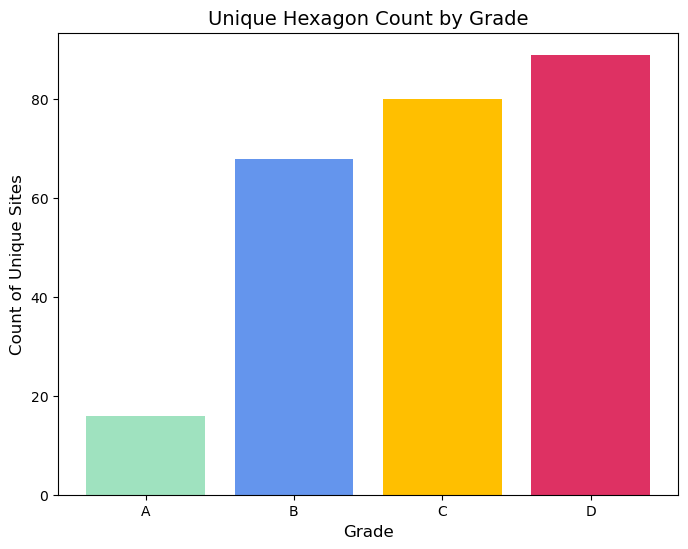

In [17]:

# ============================================================================
# 7. COUNT HEXAGONS PER GRADE
# ============================================================================

grade_count = (
    selected_hexagons
    .groupby('grade')['hex_id']
    .nunique()
    .reset_index()
    .rename(columns={'hex_id': 'unique_count'})
)

print("\nHexagon count per grade:")
print(grade_count)

# Plot bar chart
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(
    grade_count['grade'], 
    grade_count['unique_count'],
    color=[holc_colors[g] for g in grade_count['grade']]
)

ax.set_xlabel('Grade', fontsize=12)
ax.set_ylabel('Count of Unique Sites', fontsize=12)
ax.set_title('Unique Hexagon Count by Grade', fontsize=14)

#plt.tight_layout()
#plt.savefig("G:/My Drive/Chapter1_LA_redlining/results_images/unique_hex_count_100m_max_post250.png", dpi=300, bbox_inches='tight')
#plt.show()


In [18]:
# ============================================================================
# 8. EXPORT GEOJSON
# ============================================================================

selected_hexagons.to_file(
    "../data/output/sfhex_100_filtered_max_05.01.26_post250.geojson",
    driver="GeoJSON"
)

print("\nGeoJSON exported successfully!")

# ============================================================================
# 9. RESHAPE TO MATRIX (equivalent to pivot_wider)
# ============================================================================

# Drop geometry for matrix operations
ebird_matrix = (
    selected_hexagons
    .drop(columns='geometry')
    .groupby(['hex_id', 'scientific_name'])['max_observations']
    .sum()
    .reset_index()
)

# Pivot to wide format (species as rows, hex_id as columns)
ebird_matrix_wide = ebird_matrix.pivot(
    index='scientific_name',
    columns='hex_id',
    values='max_observations'
).fillna(0)

#remove species where there are only 1 or less observation across all hexagons 
#bird_matrix_wide = ebird_matrix_wide[ebird_matrix_wide.sum(axis=1) > 1]


# Now do a seperate plot for grades
ebird_matrix_grade = (
    selected_hexagons
    .drop(columns='geometry')
    .groupby(['grade', 'scientific_name'])['max_observations']
    .sum()
    .reset_index()
)

# Pivot to wide format (species as rows, hex_id as columns)
ebird_matrix_wide_grade = ebird_matrix_grade.pivot(
    index='scientific_name',
    columns='grade',
    values='max_observations'
).fillna(0)

#remove species where there are only 1 or less observation across all hexagons 
#ebird_matrix_wide_grade = ebird_matrix_wide_grade[ebird_matrix_wide_grade.sum(axis=1) > 1]


print(f"\nMatrix shape: {ebird_matrix_wide.shape}")
print(f"First few rows:\n{ebird_matrix_wide.head()}")




GeoJSON exported successfully!

Matrix shape: (169, 253)
First few rows:
hex_id                     1031_B  1035_B  1069_B  1106_C  1123_B  1141_B  \
scientific_name                                                             
Accipiter striatus            0.0     0.0     0.0     0.0     0.0     0.0   
Aechmophorus clarkii          0.0     0.0     0.0     0.0     0.0     0.0   
Aechmophorus occidentalis     0.0     0.0     0.0     0.0     0.0     0.0   
Aeronautes saxatalis          0.0     0.0     0.0     0.0     0.0     0.0   
Agelaius phoeniceus           0.0     0.0     0.0     0.0     0.0     0.0   

hex_id                     1150_B  1166_B  1201_B  1224_B  ...  828_B  837_B  \
scientific_name                                            ...                 
Accipiter striatus            0.0     0.0     0.0     0.0  ...    0.0    0.0   
Aechmophorus clarkii          0.0     0.0     0.0     0.0  ...    0.0    0.0   
Aechmophorus occidentalis     0.0     0.0     0.0     0.0  ...    

# iNEXT All Species

In [19]:
#This takes 21 minutes to run, write csv and files 

from pathlib import Path

# %pip install rpy2

from rpy2.robjects import r, globalenv
from rpy2.robjects.packages import importr
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

# Import R packages
base = importr('base')
inext_pkg = importr('iNEXT')

# Set up paths
here_path = Path.cwd()  # Or specify your project root
results_path = here_path / "data" / "Results"
results_path.mkdir(parents=True, exist_ok=True)

# Convert pandas DataFrames to R dataframes using the new context manager
with localconverter(ro.default_converter + pandas2ri.converter):
    globalenv['ebird_matrix_df'] = ro.conversion.py2rpy(ebird_matrix_wide)
    #globalenv['ebird_matrix_grades'] = ro.conversion.py2rpy(ebird_matrix_grades)

globalenv['results_path'] = str(results_path)


In [20]:

# Run complete analysis in R (takes 7 minutes)
ro.r('''
    library(iNEXT)
    
    # Run iNEXT for zones
    inext_zone <- iNEXT(ebird_matrix_df, 
                        datatype = "abundance", 
                        q = c(0, 1, 2), 
                        endpoint = max(colSums(ebird_matrix_df)))
    

    
    # -------- Process and save holcid results --------
    inext_results <- inext_zone
    data_info <- inext_results$DataInfo
    asy_est <- inext_results$AsyEst
    size_based_list <- inext_results$iNextEst
    size_based <- size_based_list$size_based
    coverage_based <- size_based_list$coverage_based
    
     
     # Save holcid results
    write.csv(data_info, 
              file = file.path(results_path, "SF_100hex_inextdatainfo_holcid_4_26_26_postspace.csv"))
    write.csv(asy_est, 
              file = file.path(results_path, "SF_100hex_asymp_holcid_4_26_26_postspace.csv"))
    write.csv(size_based, 
              file = file.path(results_path, "SF_100hex_sizebased_holcid_4_26_26_postspace.csv"))
    write.csv(coverage_based, 
              file = file.path(results_path, "SF_100hex_covbased_holcid_4_26_26_postspace.csv"))
    ''')

#These results have been updated with the 2025 data 

In [21]:
ebird_matrix_wide_grade.shape

(169, 4)

In [22]:
 # Run separate iNEXT for each grade
#This takes about 4 minutes
from rpy2.robjects import r, globalenv
from rpy2.robjects.lib import grdevices
from IPython.display import Image, display
import rpy2.robjects as ro

# Convert pandas DataFrames to R dataframes using the new context manager
with localconverter(ro.default_converter + pandas2ri.converter):
    globalenv['ebird_matrix_df_grade'] = ro.conversion.py2rpy(ebird_matrix_wide_grade)
    #globalenv['ebird_matrix_grades'] = ro.conversion.py2rpy(ebird_matrix_grades)

globalenv['results_path'] = str(results_path)



In [23]:

ro.r('''
    library(iNEXT)
    

    # Run iNEXT for zones
     
    inext_grades <- iNEXT(ebird_matrix_df_grade, 
                          datatype = "abundance", 
                          q = c(0, 1, 2), 
                          endpoint = max(colSums(ebird_matrix_df_grade)))
    
    # -------- Process and save holcid results --------
    inext_results <- inext_grades
    data_info <- inext_results$DataInfo
    asy_est <- inext_results$AsyEst
    size_based_list <- inext_results$iNextEst
    size_based <- size_based_list$size_based
    coverage_based <- size_based_list$coverage_based
    
     
    # Save holcid results
    write.csv(data_info, 
              file = file.path(results_path, "SF_100hex_inextdatainfo_grades_4_26_26_postspace.csv"))
    write.csv(asy_est, 
              file = file.path(results_path, "SF_100hex_asymp_grades_4_26_26_postspace.csv"))
    write.csv(size_based, 
              file = file.path(results_path, "SF_100hex_sizebased_grades_4_26_26_postspace.csv"))
    write.csv(coverage_based, 
              file = file.path(results_path, "SF_100hex_covbased_grades_4_26_26_postspace.csv"))
    
    '''
     )


# Inext custom plots


In [34]:

#Write out plots for inext plots 
ro.r(''' 

    library(iNEXT)
    library(ggplot2)
    library(scales)
    library(stringr)
    library(dplyr)
    
     
    # Create plots for zones
    plot_zone <- ggiNEXT(inext_grades, type=1)  # Sample-size-based R/E curve
    ggsave("inext_grades_rarefaction.png", plot_zone, width=10, height=6, dpi=150)
     

    holc_colors = c("A" = "#9FE2BF", "B" = "#6495ED", "C" = "#FFBF00", "D" = "#DE3163")
    holc_shapes = c("A" = 16, "B" = 17, "C" = 15, "D" = 4)  # circle, triangle, square, cross
     
    # -------- Process and save holcid results --------
    # Extract grade from Assemblage name
    inext_results$AsyEst$grade <- str_sub(inext_results$AsyEst$Assemblage, -1, -1)
    inext_results$iNextEst$size_based$grade <- str_sub(inext_results$iNextEst$size_based$Assemblage, -1, -1)
    inext_results$iNextEst$coverage_based$grade <- str_sub(inext_results$iNextEst$coverage_based$Assemblage, -1, -1)
    inext_results$DataInfo$grade <- str_sub(inext_results$DataInfo$Assemblage, -1, -1)

    # Create the base plot using Assemblage (which ggiNEXT recognizes)
    p <- ggiNEXT(inext_results, type = 1, facet.var = "Order.q", color.var = "Assemblage") +
        theme_light(base_size = 22) + 
        labs(x = "Number of individuals (1000)", y = "Species diversity") +
        scale_x_continuous(labels = unit_format(unit = " ", scale = 1e-3))
    
    # Extract the data and modify it to use grade instead
    p_data <- p$data
    p_data$grade <- str_sub(p_data$Assemblage, -1, -1)
    

    # Find transition points (end of rarefaction/observed and start of extrapolation)
    # For each Assemblage and Order.q, find the max point of rarefaction/observed
     
    transition_points <- p_data %>%
        filter(Method %in% c("Rarefaction", "Observed")) %>%
        group_by(Assemblage, Order.q, grade) %>%
        filter(x == max(x)) %>%
        slice(1) %>%
        ungroup()
     

    # Rebuild the plot with grade as the color variable
    final_plot <- ggplot(p_data, aes(x = x, y = y, colour = grade, fill = grade)) +
        geom_line(aes(linetype = Method), size = 1.5) +
        geom_ribbon(aes(ymin = y.lwr, ymax = y.upr), alpha = 0.2, colour = NA) +
        geom_point(data = transition_points, aes(shape = grade), size = 4) +
        facet_wrap(~ Order.q, scales = "fixed", labeller = labeller(Order.q = c("0" = "Richness", "1" = "Shannon's", "2" = "Simpson's"))) +
        scale_colour_manual(values = holc_colors, name = "Grade") + 
        scale_shape_manual(values = holc_shapes, name = "Grade") +
        scale_linetype_manual(values = c("Rarefaction" = "solid", "Observed" = "solid", "Extrapolation" = "dashed"), name = "Method") +
        scale_fill_manual(values = holc_colors, name = "Grade") + 
        theme_light(base_size = 22) + 
        theme(panel.grid.major = element_blank()) +
        labs(x = "Number of individuals (1000)", y = "Species diversity") +
        scale_x_continuous(labels = unit_format(unit = " ", scale = 1e-3))
    
    print(final_plot)
    
    # Export the figure
    ggsave("../results_images/inext_speciesaccum_grades_4.26.26_.png", 
           plot = final_plot, units = "in", width = 13, height = 7, dpi = 300)

''')

print("All iNEXT analyses complete and results saved!")
print("\nCoverage-based R/E Curves:")


All iNEXT analyses complete and results saved!

Coverage-based R/E Curves:


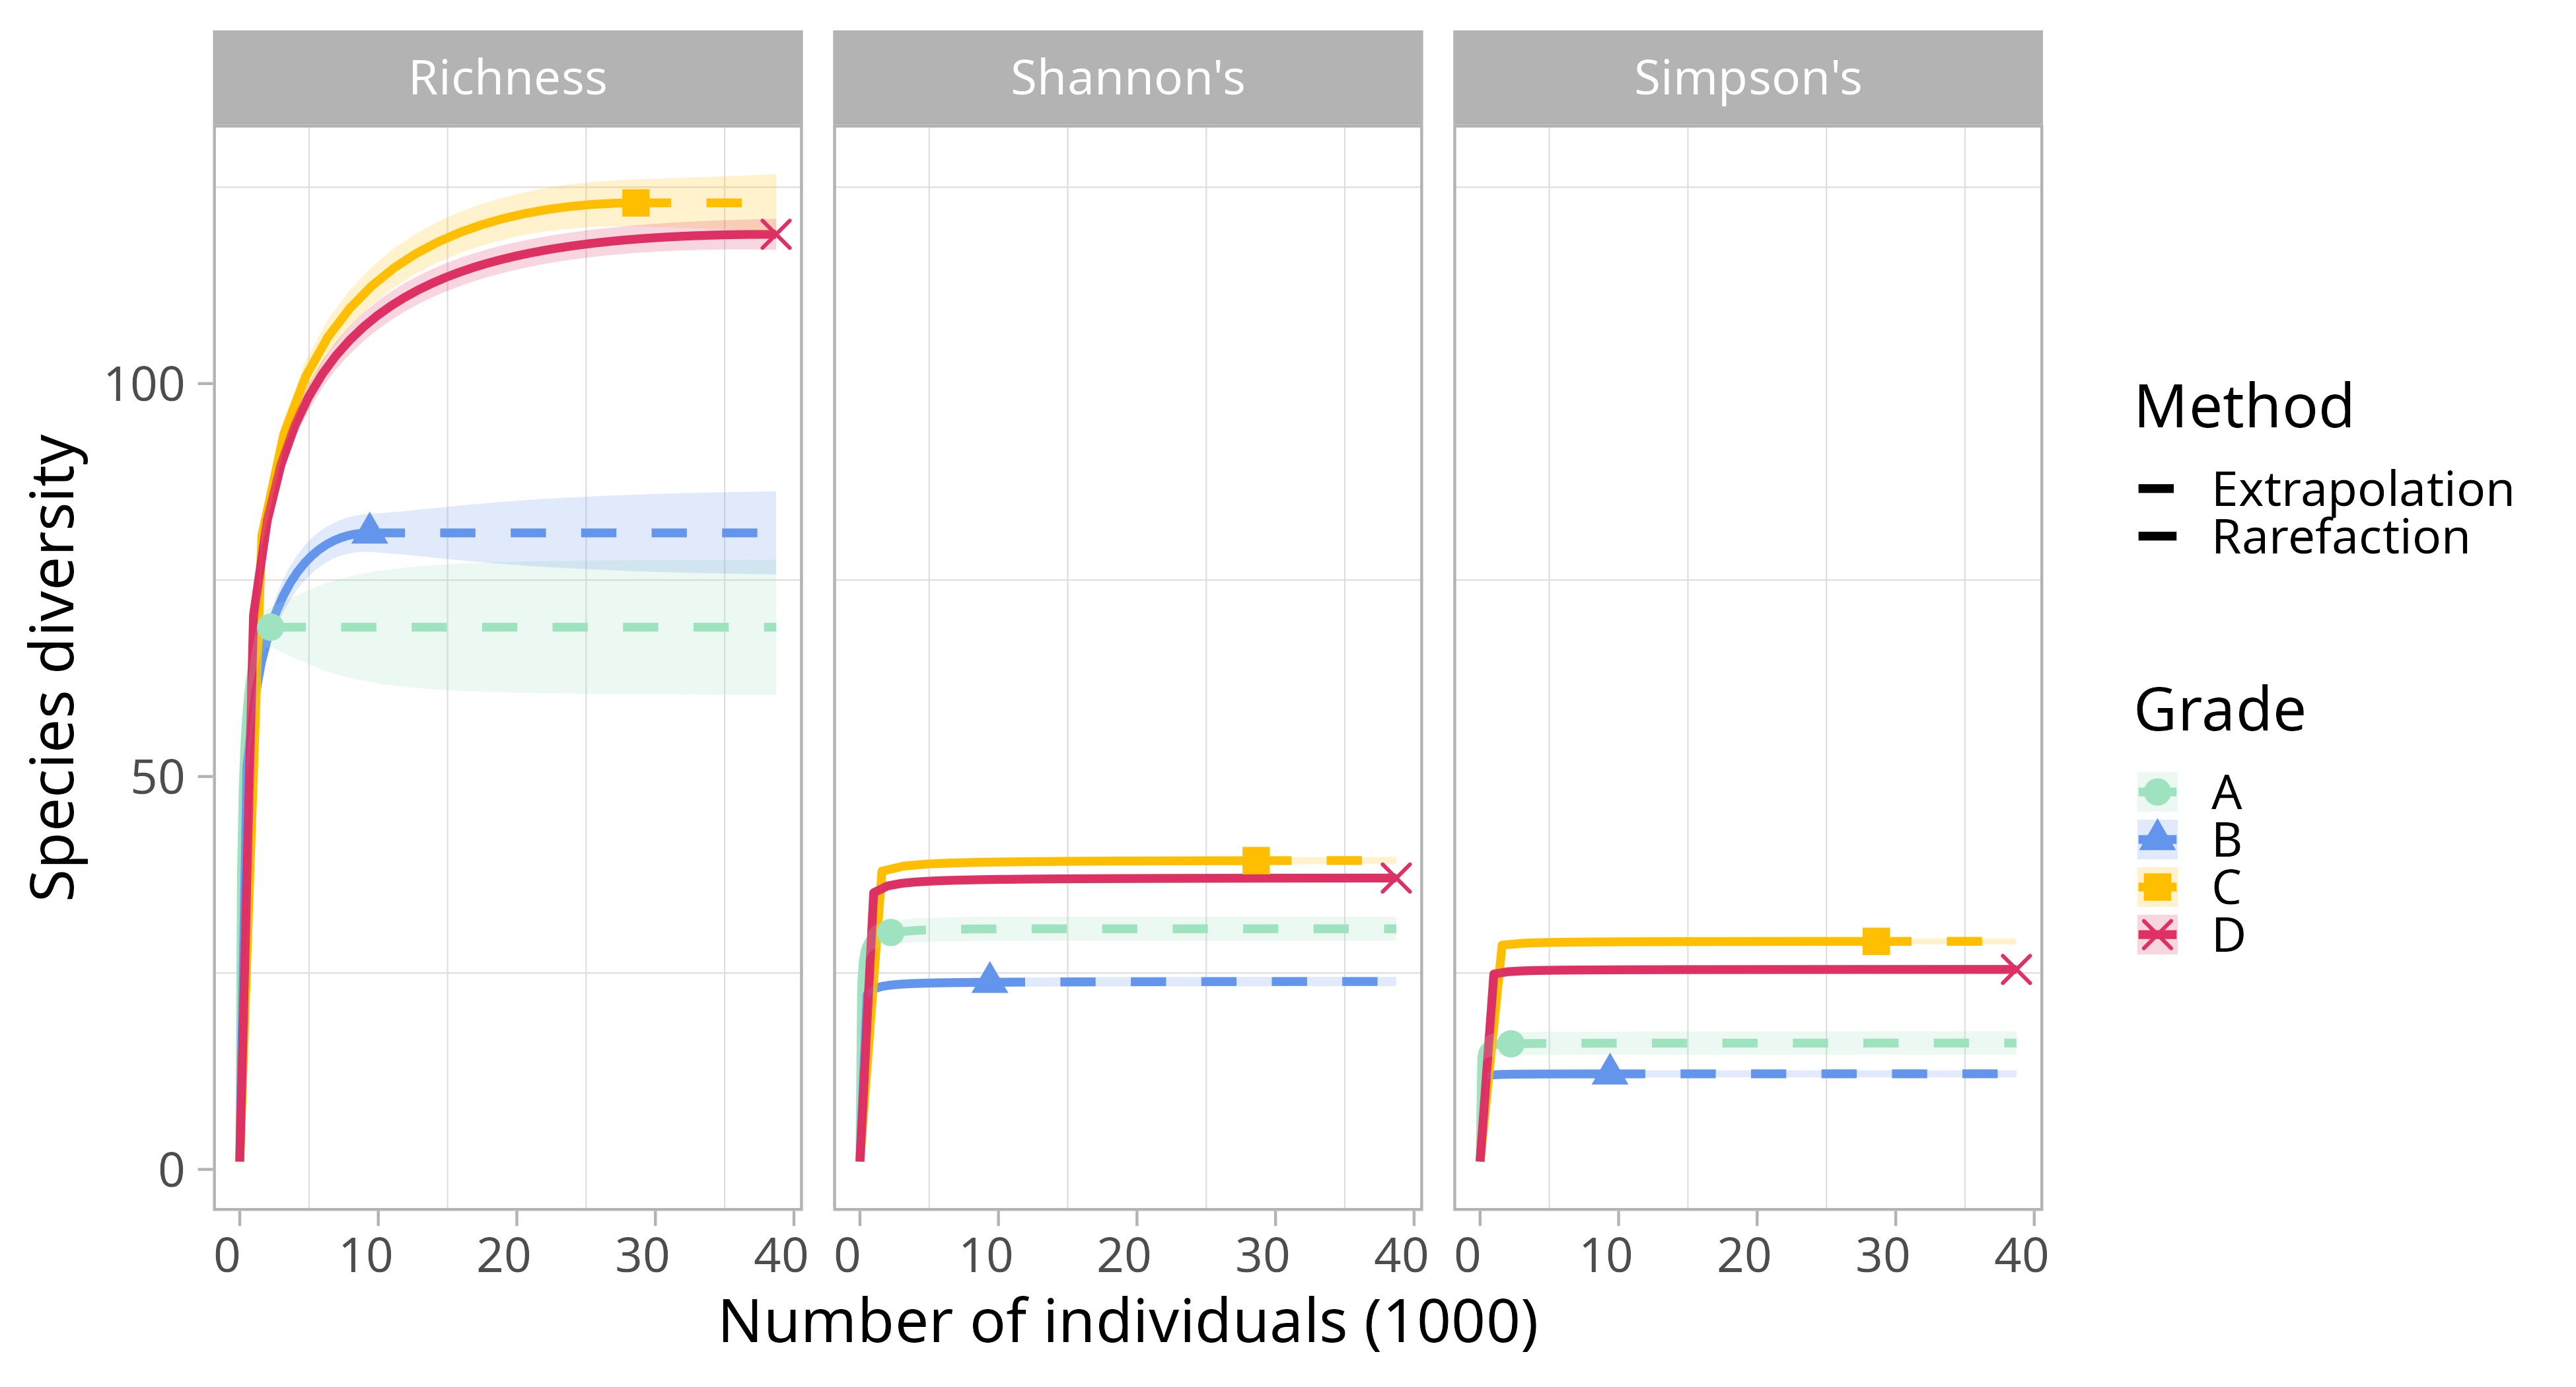

In [35]:
from pathlib import Path
from IPython.display import Image, display

# Build path more safely
here_path = Path.cwd()
image_path = here_path.parent / "results_images" / "inext_speciesaccum_grades_4.26.26_.png"

# Check if it exists
if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print(f"File not found: {image_path}")
    print(f"Looking in: {image_path.parent}")
    # Show what files ARE there
    if image_path.parent.exists():
        print("\nAvailable files:")
        for f in sorted(image_path.parent.glob("*.png")):
            print(f"  {f.name}")

In [26]:



# Get and set working directory
import os


current_dir = os.getcwd()
print(f"Python working directory: {current_dir}")

# Set R's working directory to match Python's
ro.r(f'setwd("{current_dir.replace(os.sep, "/")}")')

# Verify R's working directory
r_wd = ro.r('getwd()')[0]
print(f"R working directory: {r_wd}")


Python working directory: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code
R working directory: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Zone Rarefaction Curves:


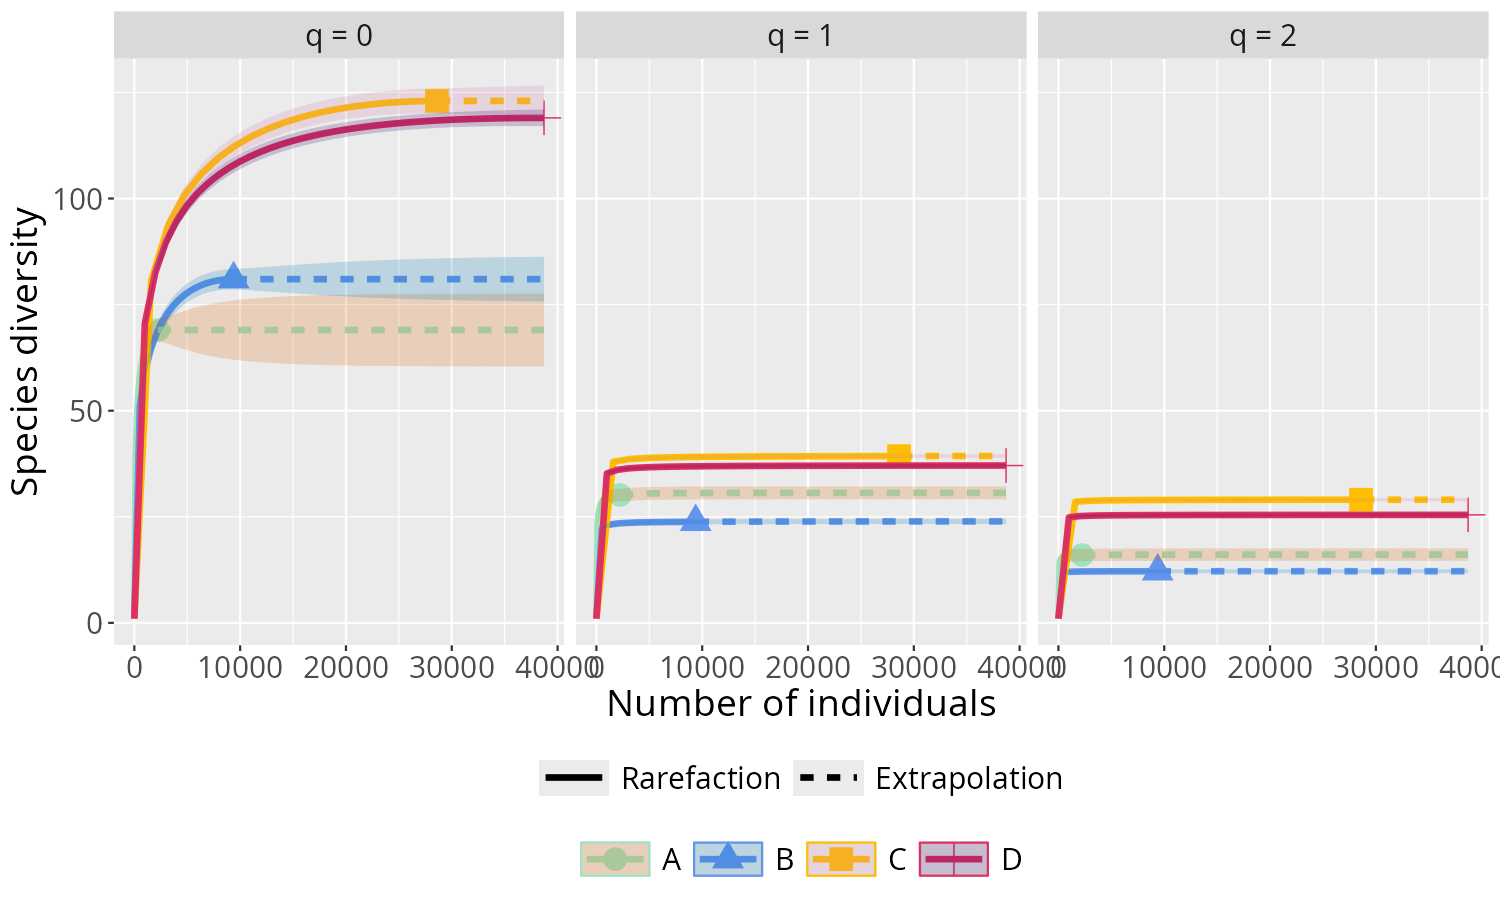


Sample Completeness Curves:


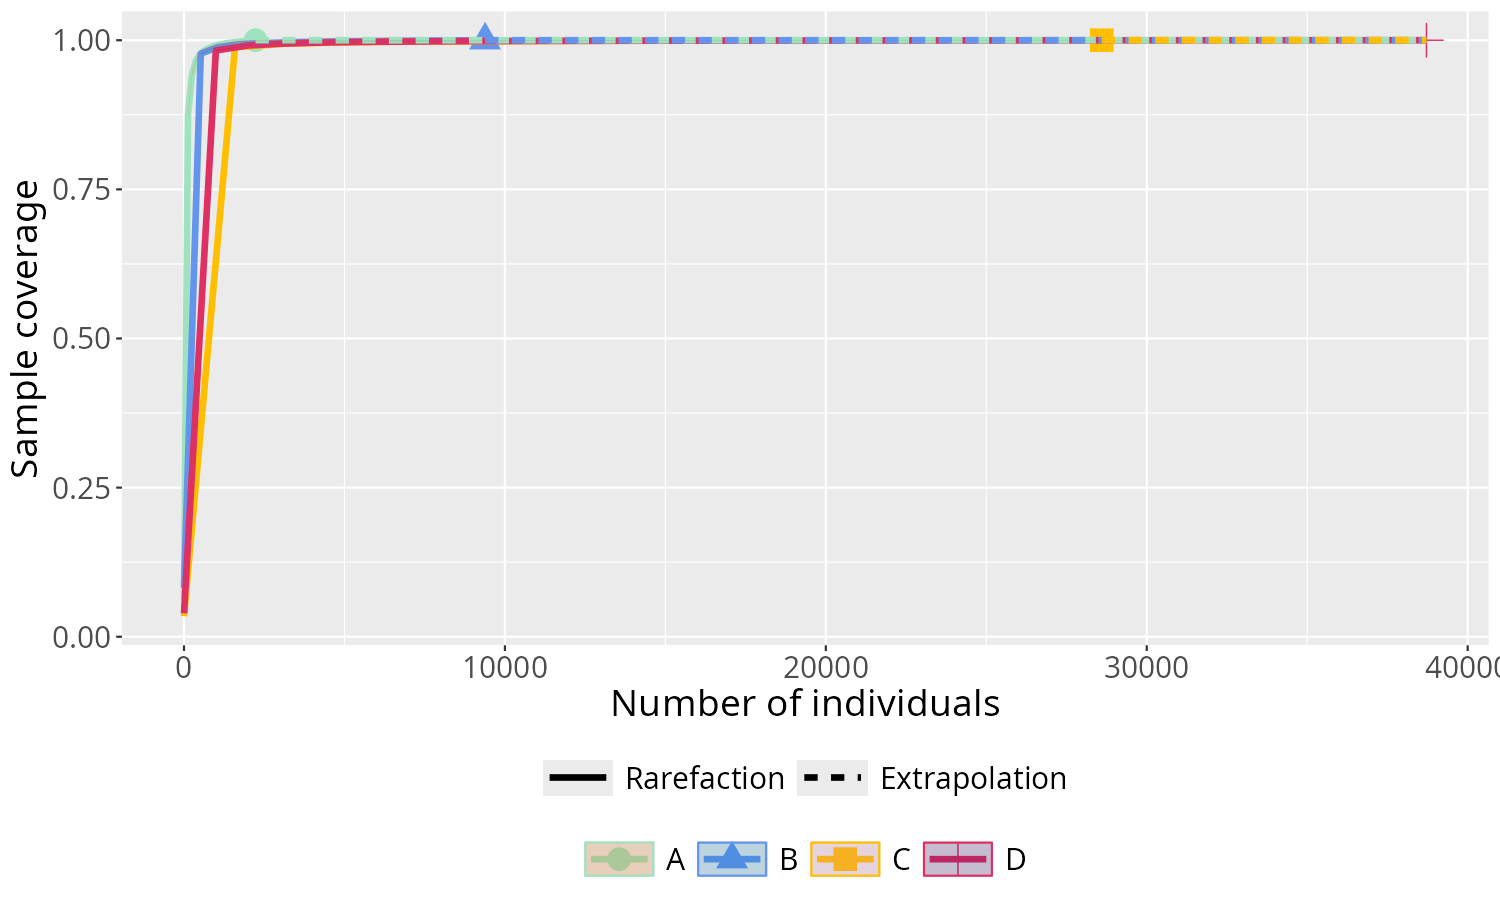


Coverage-based R/E Curves:


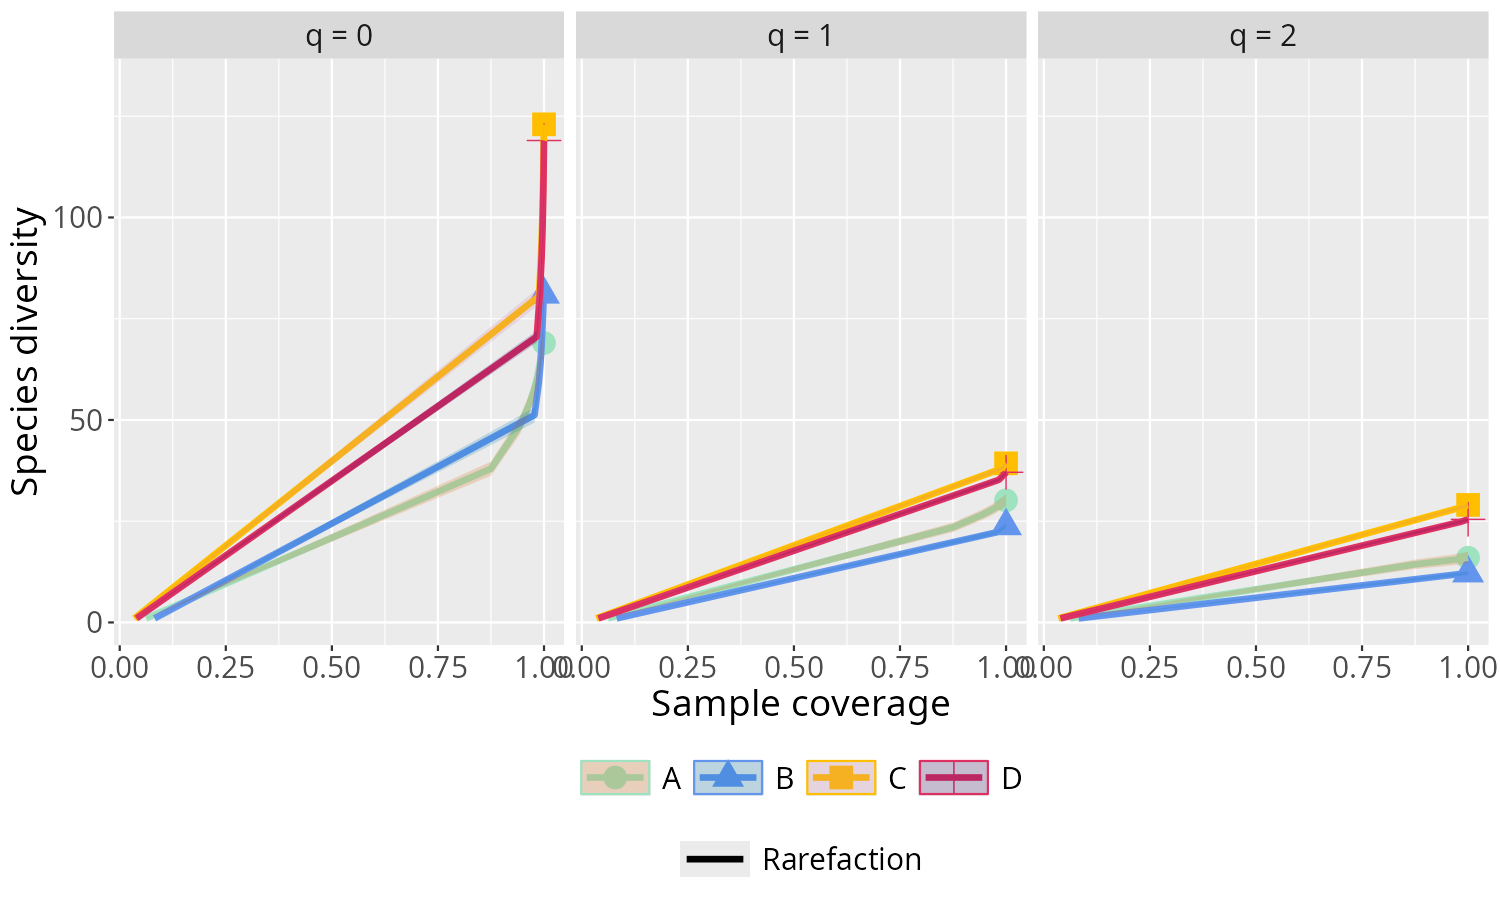

In [27]:


# After running your iNEXT analysis, create and save plots

ro.r('''
    library(iNEXT)
    library(ggplot2)
     
    holc_colors <- c("#9FE2BF", "#6495ED", "#FFBF00", "#DE3163")

    # Create plots for zones
    plot_zone <- ggiNEXT(inext_grades, type=1, facet.var="Order.q", color.var="Assemblage")  # Sample-size-based R/E curve
    plot_zone <- plot_zone + scale_color_manual(values=holc_colors)  # Optional: set custom colors for grades
    ggsave("../results_images/inext_grades_rarefaction_4.26.26.png", plot_zone, width=10, height=6, dpi=150)
    
    plot_zone_cov <- ggiNEXT(inext_grades, type=2, facet.var="Order.q", color.var="Assemblage")  # Sample completeness curve
    plot_zone_cov <- plot_zone_cov + scale_color_manual(values=holc_colors)  # Optional: set custom colors for grades
     ggsave("../results_images/inext_grades_coverage_4.26.26.png", plot_zone_cov, width=10, height=6, dpi=150)
    
    plot_zone_cov_re <- ggiNEXT(inext_grades, type=3, facet.var="Order.q", color.var="Assemblage")  # Coverage-based R/E curve
    plot_zone_cov_re <- plot_zone_cov_re + scale_color_manual(values=holc_colors)  # Optional: set custom colors for grades
    ggsave("../results_images/inext_grades_coverage_re_4.26.26.png", plot_zone_cov_re, width=10, height=6, dpi=150)
''')


print("Zone Rarefaction Curves:")
display(Image(filename="../results_images/inext_grades_rarefaction_4.26.26.png"))

print("\nSample Completeness Curves:")
display(Image(filename="../results_images/inext_grades_coverage_4.26.26.png"))

print("\nCoverage-based R/E Curves:")
display(Image(filename="../results_images/inext_grades_coverage_re_4.26.26.png"))

# All Species

In [28]:

# Build path more safely
here_path = Path.cwd()
image_path = here_path.parent / "Results" / "SF_100hex_asymp_holcid_4_26_26_postspace.csv"


# Check if it exists
if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print(f"File not found: {image_path}")
    print(f"Looking in: {image_path.parent}")
    # Show what files ARE there
    if image_path.parent.exists():
        print("\nAvailable files:")
        for f in sorted(image_path.parent.glob("*.csv")):
            print(f"  {f.name}")

File not found: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv
Looking in: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Results


In [9]:
#Visualization of iNEXT results
# Python script for Boxplot visualizations
# Converted from R to Python

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels 
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 300

# ============================================================================
# SECTION 1: Boxplot visualizations by hex-id
# ============================================================================

# Load data - assuming inext_results is a dictionary with 'AsyEst' key
# You'll need to adjust the data loading based on your actual data structure

inext_results =  pd.read_csv("./data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv")  # Replace with actual loading function


# Extract grade from Assemblage column (last character)
def extract_grade(assemblage):
    """Extract the last character from assemblage string as grade"""
    return str(assemblage)[-1]

# Assuming box_data is a DataFrame
box_data = inext_results.copy()
box_data['grade'] = box_data['Assemblage'].apply(extract_grade)
box_data['grade'] = box_data['grade'].astype('category')



# Coveraged-based Asymptopes

In [15]:

cov_results =  pd.read_csv("./data/Results/SF_100hex_covbased_holcid_4_26_26_postspace.csv")  # Replace with actual loading function
cov_results


,Unnamed: 0,Assemblage,SC,m,Method,Order.q,qD,qD.LCL,qD.UCL
0,1,1031_B,0.431579,1,Rarefaction,0,1.000000,0.840990,1.159010
1,2,1031_B,0.652630,2,Rarefaction,0,1.568418,1.025939,2.110898
2,3,1031_B,0.768420,3,Rarefaction,0,1.915785,1.260084,2.571486
3,4,1031_B,0.832739,4,Rarefaction,0,2.147365,1.456060,2.838670
4,5,1031_B,0.871775,5,Rarefaction,0,2.314629,1.595918,3.033341
...,...,...,...,...,...,...,...,...,...
11773,53117,990_B,0.994405,84,Rarefaction,2,4.661431,3.781322,5.541540
11774,54106,990_B,0.996156,90,Rarefaction,2,4.675180,3.787634,5.562727
11775,55100,990_B,0.997638,96,Rarefaction,2,4.687278,3.791996,5.582560
11776,56100,990_B,0.998909,102,Rarefaction,2,4.698004,3.793815,5.602193


In [16]:

# Extract grade from Assemblage column (last character)
def extract_grade(assemblage):
    """Extract the last character from assemblage string as grade"""
    return str(assemblage)[-1]

# Assuming box_data is a DataFrame
box_data = cov_results.copy()
box_data['hex_id'] = box_data['Assemblage']  # Keep original as hex_id
box_data['grade'] = box_data['Assemblage'].apply(extract_grade)
box_data['grade'] = box_data['grade'].astype('category')

print(cov_results)
print(box_data)


       Unnamed: 0 Assemblage        SC    m       Method  Order.q        qD  \
0               1     1031_B  0.431579    1  Rarefaction        0  1.000000   
1               2     1031_B  0.652630    2  Rarefaction        0  1.568418   
2               3     1031_B  0.768420    3  Rarefaction        0  1.915785   
3               4     1031_B  0.832739    4  Rarefaction        0  2.147365   
4               5     1031_B  0.871775    5  Rarefaction        0  2.314629   
...           ...        ...       ...  ...          ...      ...       ...   
11773       53117      990_B  0.994405   84  Rarefaction        2  4.661431   
11774       54106      990_B  0.996156   90  Rarefaction        2  4.675180   
11775       55100      990_B  0.997638   96  Rarefaction        2  4.687278   
11776       56100      990_B  0.998909  102  Rarefaction        2  4.698004   
11777       57100      990_B  1.000000  109     Observed        2  4.709076   

         qD.LCL    qD.UCL  
0      0.840990  1.1590

In [ ]:
df = box_data.copy()

# Test multiple thresholds
for threshold in [0.80, 0.85, 0.90, 0.95]:
    counts = (
        df.query(f'SC > {threshold} and Method == "Rarefaction" or Method == "Observed"')
        .groupby('grade')['Assemblage']
        .nunique()
    )
    print(f"\nCoverage > {threshold}:")
    print(counts)
    print(f"Total: {counts.sum()}")

#We can use 90% coverage 

"""
Coverage > 0.9:
grade
A    16
B    68
C    80
D    89
Name: Assemblage, dtype: int64
Total: 253
"""


# By grade and diversity order
sampling_by_grade_q = (
    df.query('SC > 0.90 and Method == "Rarefaction" or Method == "Observed"')
    .groupby(['grade', 'Order.q'])
    .agg(
        n_hexagons=('Assemblage', 'nunique')
    )
    .reset_index()
    .pivot(index='grade', columns='Order.q', values='n_hexagons')
)

print("\nHexagons achieving >0.85 coverage by grade and diversity order:")
print(sampling_by_grade_q)


Coverage > 0.8:
grade
A    16
B    68
C    80
D    89
Name: Assemblage, dtype: int64
Total: 253

Coverage > 0.85:
grade
A    16
B    68
C    80
D    89
Name: Assemblage, dtype: int64
Total: 253

Coverage > 0.9:
grade
A    16
B    68
C    80
D    89
Name: Assemblage, dtype: int64
Total: 253

Coverage > 0.95:
grade
A    16
B    68
C    80
D    89
Name: Assemblage, dtype: int64
Total: 253

Hexagons achieving >0.85 coverage by grade and diversity order:
Order.q   0   1   2
grade              
A        16  16  16
B        68  68  68
C        80  80  80
D        89  89  89


In [37]:
# Test multiple thresholds
for threshold in [0.80, 0.85, 0.90, 0.95]:
    counts = (
        df.query(f'SC > {threshold}')
        .groupby('grade')
        .nunique()
    )
    print(f"\nCoverage > {threshold}:")
    print(counts)
    print(f"Total: {counts.sum()}")


Coverage > 0.8:
       Unnamed: 0  Assemblage   SC    m  Method  Order.q    qD  qD.LCL  \
grade                                                                    
A             615          16  190  105       2        3   608     615   
B            2316          68  697  202       2        3  2233    2305   
C            3090          80  943  333       2        3  3002    3081   
D            3150          89  949  274       2        3  3025    3137   

       qD.UCL  hex_id  
grade                  
A         615      16  
B        2305      68  
C        3080      80  
D        3137      89  
Total: Unnamed: 0    9171
Assemblage     253
SC            2779
m              914
Method           8
Order.q         12
qD            8868
qD.LCL        9138
qD.UCL        9137
hex_id         253
dtype: int64

Coverage > 0.85:
       Unnamed: 0  Assemblage   SC    m  Method  Order.q    qD  qD.LCL  \
grade                                                                    
A             570 

In [30]:

# Split data by diversity type
def split_by_diversity(box_data):
    """Split dataframe by diversity type"""
    df_shannons = box_data[box_data['Diversity'] == "Shannon diversity"].copy()
    df_simpsons = box_data[box_data['Diversity'] == "Simpson diversity"].copy()
    df_richness = box_data[box_data['Diversity'] == "Species richness"].copy()
    return df_shannons, df_simpsons, df_richness

df_shannons, df_simpsons, df_richness = split_by_diversity(box_data)

print(df_shannons.head())

KeyError: 'Diversity'

# Kruskal Wallis

In [31]:
from scipy.stats import kruskal


# Separate the data for each grade
# Start with individual testing for each grade 


# ========= Shannons ============

a = df_shannons[df_shannons['grade'] == 'A']['Estimator']
b = df_shannons[df_shannons['grade'] == 'B']['Estimator']
c = df_shannons[df_shannons['grade'] == 'C']['Estimator']
d = df_shannons[df_shannons['grade'] == 'D']['Estimator']
                    

# Perform the Kruskal-Wallis H-test
h_statistic, p_value = kruskal(a,b,c,d)

# Calculate the degrees of freedom
k = len(df_shannons['grade'].unique())
df = k - 1

print("Kruska-Wallis for Shannons")
print("H-statistic:", h_statistic)
print("p-value:", p_value)
print("Degrees of freedom:", df)


# ========= Simpsons =========== #
a = df_simpsons[df_simpsons['grade'] == 'A']['Estimator']
b = df_simpsons[df_simpsons['grade'] == 'B']['Estimator']
c = df_simpsons[df_simpsons['grade'] == 'C']['Estimator']
d = df_simpsons[df_simpsons['grade'] == 'D']['Estimator']
                    

# Perform the Kruskal-Wallis H-test
h_statistic, p_value = kruskal(a,b,c,d)

# Calculate the degrees of freedom
k = len(df_shannons['grade'].unique())
df = k - 1

print("Kruska-Wallis for Simpsons")


print("H-statistic:", h_statistic)
print("p-value:", p_value)
print("Degrees of freedom:", df)

# ========= Richness ========== #
a = df_richness[df_richness['grade'] == 'A']['Estimator']
b = df_richness[df_richness['grade'] == 'B']['Estimator']
c = df_richness[df_richness['grade'] == 'C']['Estimator']
d = df_richness[df_richness['grade'] == 'D']['Estimator']
                    

# Perform the Kruskal-Wallis H-test
h_statistic, p_value = kruskal(a,b,c,d)

# Calculate the degrees of freedom
k = len(df_shannons['grade'].unique())
df = k - 1


print("Kruska-Wallis for Richness")
print("H-statistic:", h_statistic)
print("p-value:", p_value)
print("Degrees of freedom:", df)

#Export the df to generate plots in R 


df_richness.to_csv("../data/ouput/kruskal_dunn/kruskaldunn_richness_4.26.26.csv", index=False)
df_simpsons.to_csv("../data/ouput/kruskal_dunn/kruskaldunn_simpsons_4.26.26.csv", index=False)
df_shannons.to_csv("../data/ouput/kruskal_dunn/kruskaldunn_shannons_4.26.26.csv", index=False)

#The only one that shows us any significance is Richness

"""
Kruska-Wallis for Shannons
H-statistic: 0.5245359066008746
p-value: 0.9134688448999204
Degrees of freedom: 3

Kruska-Wallis for Simpsons
H-statistic: 0.38654247431076727
p-value: 0.94300825786423
Degrees of freedom: 3

Kruska-Wallis for Richness
H-statistic: 2.1134430644617535
p-value: 0.5491979310682438
Degrees of freedom: 3

"""



Kruska-Wallis for Shannons
H-statistic: 7.009851617083235
p-value: 0.07158442996243454
Degrees of freedom: 3
Kruska-Wallis for Simpsons
H-statistic: 6.581415192519559
p-value: 0.08650639934094775
Degrees of freedom: 3
Kruska-Wallis for Richness
H-statistic: 6.041675596078884
p-value: 0.10960012786893032
Degrees of freedom: 3


OSError: Cannot save file into a non-existent directory: '../data/ouput/kruskal_dunn'

In [ ]:
#Now we use Dunn to see the difference between different groups
#%pip install scikit_posthocs

from scikit_posthocs import posthoc_dunn

# posthoc dunn test, with correction for multiple testing
shannon_dunn_df = posthoc_dunn(
    df_shannons, val_col="Estimator", group_col="grade", p_adjust="fdr_bh"
)

# posthoc dunn test, with correction for multiple testing
simpsons_dunn_df = posthoc_dunn(
    df_simpsons, val_col="Estimator", group_col="grade", p_adjust="fdr_bh"
)

# posthoc dunn test, with correction for multiple testing
richness_dunn_df = posthoc_dunn(
    df_richness, val_col="Estimator", group_col="grade", p_adjust="fdr_bh"
)

print("Shannon's Dunn")
print(shannon_dunn_df)

print("Simpson's Dunn")
print(simpsons_dunn_df)

print("Simpsons's Dunn")
print(richness_dunn_df)


Shannon's Dunn
          A         B         C         D
A  1.000000  0.417851  0.718632  0.718632
B  0.417851  1.000000  0.052730  0.414007
C  0.718632  0.052730  1.000000  0.411843
D  0.718632  0.414007  0.411843  1.000000
Simpson's Dunn
          A         B         C         D
A  1.000000  0.552306  0.638606  0.849962
B  0.552306  1.000000  0.064066  0.434826
C  0.638606  0.064066  1.000000  0.434826
D  0.849962  0.434826  0.434826  1.000000
Simpsons's Dunn
          A         B         C         D
A  1.000000  0.463434  0.830835  0.636235
B  0.463434  1.000000  0.106907  0.472411
C  0.830835  0.106907  1.000000  0.411760
D  0.636235  0.472411  0.411760  1.000000


In [ ]:
con.execute("""
    CREATE OR REPLACE TABLE ebird AS
    SELECT * FROM read_parquet('../data/output/april_2026/observations_max_prespatial.parquet');
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Error: TProtocolException: Invalid data

In [ ]:
con.execute("DESCRIBE ebird").fetchall()

[('checklist_id', 'VARCHAR', 'YES', None, None, None),
 ('last_edited_date', 'TIMESTAMP', 'YES', None, None, None),
 ('country', 'VARCHAR', 'YES', None, None, None),
 ('country_code', 'VARCHAR', 'YES', None, None, None),
 ('state', 'VARCHAR', 'YES', None, None, None),
 ('state_code', 'VARCHAR', 'YES', None, None, None),
 ('county', 'VARCHAR', 'YES', None, None, None),
 ('county_code', 'VARCHAR', 'YES', None, None, None),
 ('iba_code', 'VARCHAR', 'YES', None, None, None),
 ('bcr_code', 'BIGINT', 'YES', None, None, None),
 ('usfws_code', 'VARCHAR', 'YES', None, None, None),
 ('atlas_block', 'VARCHAR', 'YES', None, None, None),
 ('locality', 'VARCHAR', 'YES', None, None, None),
 ('locality_id', 'VARCHAR', 'YES', None, None, None),
 ('locality_type', 'VARCHAR', 'YES', None, None, None),
 ('latitude', 'DOUBLE', 'YES', None, None, None),
 ('longitude', 'DOUBLE', 'YES', None, None, None),
 ('observation_date', 'DATE', 'YES', None, None, None),
 ('time_observations_started', 'TIME', 'YES', Non

# Habitat Native and Nonnative 

In [ ]:
# Try skipping the first line(s)
sample = con.execute("""
    SELECT * 
    FROM read_csv(
        '/home/oliver/Downloads/ebd_US-CA-075_201001_202512_smp_relMar-2026/ebd_US-CA-075_201001_202512_smp_relMar-2026.txt',
        delim='\t',
        header=true,
        normalize_names=true)
    LIMIT 1
""").df()

print("Columns after skipping:")
print(sample.columns.tolist())

Columns after skipping:
['global_unique_identifier', 'last_edited_date', 'taxonomic_order', 'category', 'taxon_concept_id', 'common_name', 'scientific_name', 'subspecies_common_name', 'subspecies_scientific_name', 'exotic_code', 'observation_count', 'breeding_code', 'breeding_category', 'behavior_code', 'agesex', 'country', 'country_code', 'state', 'state_code', 'county', 'county_code', 'iba_code', 'bcr_code', 'usfws_code', 'atlas_block', 'locality', 'locality_id', 'locality_type', 'latitude', 'longitude', 'observation_date', 'time_observations_started', 'observer_id', 'observer_orcid_id', 'sampling_event_identifier', 'observation_type', 'protocol_name', 'protocol_code', 'project_names', 'project_identifiers', 'duration_minutes', 'effort_distance_km', 'effort_area_ha', 'number_observers', 'all_species_reported', 'group_identifier', 'has_media', 'approved', 'reviewed', 'reason', 'checklist_comments', 'species_comments', 'column52']


In [ ]:
# This will convert "SCIENTIFIC NAME" to "scientific_name" automatically
con.execute("""
    CREATE TABLE exotic AS
        SELECT 
            scientific_name,
            exotic_code
        FROM read_csv(
            '/home/oliver/Downloads/ebd_US-CA-075_201001_202512_smp_relMar-2026/ebd_US-CA-075_201001_202512_smp_relMar-2026.txt',
            delim='\t',
            header=true,
            normalize_names=true, 
            ignore_errors=true)
""")


# Check for conflicts
conflicts = con.execute("""
    SELECT 
        scientific_name, 
        COUNT(DISTINCT exotic_code) as num_codes
    FROM exotic
    GROUP BY scientific_name
    HAVING COUNT(DISTINCT exotic_code) > 1
""").fetchdf()


print(f"Species with conflicting exotic codes: {len(conflicts)}")

exotic_df = con.execute("""
    SELECT DISTINCT 
        scientific_name, 
        exotic_code
    FROM exotic
""").fetchdf()

print(f"Total unique species: {len(exotic_df)}")

Species with conflicting exotic codes: 2
Total unique species: 669


In [ ]:



# Load AVONET trait data
avonet_path = '../data/dependent_var/AVONET2_eBird.csv'

avotrait = pd.read_csv(avonet_path)

#Load selected hexagon data
avo_hex_path = '../data/output/sfhex_100_filtered_max_05.01.26_post250.geojson'


selected_hexagons = gpd.read_file(avo_hex_path)




In [ ]:

## Merge with Selected Hexagons and Process Habitat Guilds and exotic_df

ebird_habitat = selected_hexagons.merge(
    avotrait[['Species2', 'Habitat']], 
    left_on='scientific_name', 
    right_on='Species2', 
    how='left'
).merge(
    exotic_df[['scientific_name', 'exotic_code']], 
    on='scientific_name', 
    how='left'
)


print(ebird_habitat.columns)

ebird_habitat_df = ebird_habitat.drop(columns=['geometry'])

# Create table directly from DataFrame
con.execute("CREATE OR REPLACE TABLE ebird_habitat_df AS SELECT * FROM ebird_habitat_df")


Index(['scientific_name', 'hex_id', 'max_observations', 'grade', 'geometry',
       'Species2', 'Habitat', 'exotic_code'],
      dtype='str')


In [ ]:

# Combine similar habitat guilds
def consolidate_habitats(habitat):
    """Combine similar habitat types into broader categories"""
    if pd.isna(habitat):
        return habitat
    elif habitat in ['Forest', 'Woodland']:
        return 'Trees'
    elif habitat in ['Grassland', 'Shrubland']:
        return 'ShrubGrass'
    elif habitat in ['Wetland', 'Coastal', 'Marine', 'Riverine']:
        return 'Water'
    else:
        return habitat

ebird_habitat['Habitat'] = ebird_habitat['Habitat'].apply(consolidate_habitats)

# Filter out NA and Rock habitats
ebird_hab_filter = ebird_habitat[
    ~ebird_habitat['Habitat'].isin(['Rock']) & 
    ebird_habitat['Habitat'].notna()
].copy()

# Check unique habitats
print("Unique habitats:", ebird_hab_filter['Habitat'].unique())

# Subset by habitat type
ebird_trees = ebird_hab_filter[ebird_hab_filter['Habitat'] == 'Trees'].copy()
ebird_water = ebird_hab_filter[ebird_hab_filter['Habitat'] == 'Water'].copy()
ebird_shrubgrass = ebird_hab_filter[ebird_hab_filter['Habitat'] == 'ShrubGrass'].copy()
ebird_human = ebird_hab_filter[ebird_hab_filter['Habitat'] == 'Human Modified'].copy()

hab_dict = {
    'trees': ebird_trees,
    'water': ebird_water,
    'shrubgrass': ebird_shrubgrass,
    'human': ebird_human
}



Unique habitats: <ArrowStringArray>
['Water', 'Trees', 'ShrubGrass', 'Human Modified']
Length: 4, dtype: str


In [ ]:


## Reshape Data for Analysis

def reshape_for_analysis(gdf, filter_min_species=2):
    """
    Reshape bird observation data from long to wide format
    and filter for sites with minimum species count
    
    Parameters:
    -----------
    gdf : GeoDataFrame
        Input data with scientific_name, hex_id, max_observations
    filter_min_species : int
        Minimum number of species required per hex_id
    
    Returns:
    --------
    DataFrame : Wide format data with species as rows, hex_ids as columns
    """
    # Drop geometry and select relevant columns
    df = gdf.drop(columns='geometry' if 'geometry' in gdf.columns else [])
    df = df[['scientific_name', 'hex_id', 'max_observations']].copy()
    
    # Group and summarize
    df_summary = df.groupby(['hex_id', 'scientific_name'], as_index=False).agg({
        'max_observations': 'sum'
    })
    
    # Filter for observations > 0
    df_summary = df_summary[df_summary['max_observations'] > 0]
    
    # Count species per hex_id
    species_count = df_summary.groupby('hex_id')['scientific_name'].nunique()
    valid_hexes = species_count[species_count >= filter_min_species].index
    
    # Filter for valid hexes
    df_filtered = df_summary[df_summary['hex_id'].isin(valid_hexes)]
    
    # Pivot to wide format
    df_wide = df_filtered.pivot(
        index='scientific_name',
        columns='hex_id',
        values='max_observations'
    ).fillna(0)
    
    return df_wide

# Reshape each habitat type
reshaped_dict = {}

for hab_name, hab_data in hab_dict.items():
    print(f"Processing {hab_name}...")
    reshaped_dict[f'ebird_{hab_name}_reshape'] = reshape_for_analysis(hab_data)
    print(f"  Shape: {reshaped_dict[f'ebird_{hab_name}_reshape'].shape}")

## Extract Native and Non-Native Species

# Query native status from DuckDB
native_status = con.execute("""
    SELECT 
        "scientific_name" AS scientific_name,
        "exotic_code" AS exotic_code
    FROM ebird_habitat_df
""").fetchdf()



data_dir = '../data'

# Non-native are only N, X, P
ebird_nonnative = native_status[
    native_status['exotic_code'].isin(['N', 'X', 'P'])
]['scientific_name'].unique()

# Everything else is native
ebird_native = native_status[
    ~native_status['exotic_code'].isin(['N', 'X', 'P'])
]['scientific_name'].unique()

# Save species lists
pd.DataFrame({'scientific_name': ebird_native}).to_csv(
    f"{data_dir}/native_species.csv",  # Use f-string with f prefix
    index=False
)


pd.DataFrame({'scientific_name': ebird_nonnative}).to_csv(
    f"{data_dir}/nonnative_species.csv", 
    index=False
)

print(f"Native species: {len(ebird_native)}")
print(f"Non-native species: {len(ebird_nonnative)}")


Processing trees...
  Shape: (66, 164)
Processing water...
  Shape: (40, 21)
Processing shrubgrass...
  Shape: (44, 123)
Processing human...
  Shape: (10, 102)
Native species: 161
Non-native species: 9


In [ ]:


## Create Native and Non-Native Datasets

# Filter selected_hexagons for native species
ebird_native_df = selected_hexagons[
    selected_hexagons['scientific_name'].isin(ebird_native)
].copy()

# Filter for non-native species
ebird_nonnative_df = selected_hexagons[
    selected_hexagons['scientific_name'].isin(ebird_nonnative)
].copy()

# Reshape both datasets
ebird_native_reshape= reshape_for_analysis(ebird_native_df)
ebird_nonnative_reshape= reshape_for_analysis(ebird_nonnative_df)

# Add to reshaped dictionary
reshaped_dict['ebird_native_reshape'] = ebird_native_reshape
reshaped_dict['ebird_nonnative_reshape'] = ebird_nonnative_reshape

print(f"Native reshape shape: {ebird_native_reshape.shape}")
print(f"Non-native reshape shape : {ebird_nonnative_reshape.shape}")


## Prepare Data for iNEXT Analysis

from joblib import Parallel, delayed
import multiprocessing

# Get number of cores
n_cores = multiprocessing.cpu_count()
print(f"Available cores: {n_cores}")

def prepare_for_inext(df):
    """
    Prepare dataframe for iNEXT analysis
    Remove rows/columns with all zeros or NAs
    """
    # Remove rows with all NaN
    df_clean = df.dropna(how='all')
    
    # Remove columns with sum = 0
    df_clean = df_clean.loc[:, (df_clean.sum(axis=0) != 0)]
    
    # Remove rows with sum = 0
    df_clean = df_clean.loc[(df_clean.sum(axis=1) != 0), :]
    
    return df_clean



print("Processing data for iNEXT analysis...")
inext_data_grades = {}

for name, df in reshaped_dict.items():
    print(f"Processing {name}...")
    inext_data_grades[name] = prepare_for_inext(df)
    print(f"  ✓ Shape: {inext_data_grades[name].shape}")

print("\nAll processing complete!")


Native reshape shape: (160, 233)
Non-native reshape shape : (9, 67)
Available cores: 8
Processing data for iNEXT analysis...
Processing ebird_trees_reshape...
  ✓ Shape: (66, 164)
Processing ebird_water_reshape...
  ✓ Shape: (40, 21)
Processing ebird_shrubgrass_reshape...
  ✓ Shape: (44, 123)
Processing ebird_human_reshape...
  ✓ Shape: (10, 102)
Processing ebird_native_reshape...
  ✓ Shape: (160, 233)
Processing ebird_nonnative_reshape...
  ✓ Shape: (9, 67)

All processing complete!


# NMDS of Habitat Guilds



In [ ]:
#Run for Zones/Neighborhoods 
#This takes time to run, write csv and files (About 70 minutes)

from rpy2.robjects import r, globalenv
from rpy2.robjects.packages import importr
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from pathlib import Path
import time

# Import R packages
base = importr('base')
inext_pkg = importr('iNEXT')

# Set up paths
here_path = Path.cwd()  # Or specify your project root
results_path = "../data/Results"
#results_path.mkdir(parents=True, exist_ok=True)

globalenv['results_path'] = str(results_path)

# Dictionary to store results
all_inext_results = {}

# Process each dataframe in the dictionary
for dataset_name, df in inext_data_grades.items():
    print(f"\n{'='*60}")
    print(f"Processing: {dataset_name}")
    print(f"Shape: {df.shape}")
    print(f"{'='*60}")
    
    start_time = time.time()
    
    try:
        # Convert pandas DataFrame to R dataframe
        with localconverter(ro.default_converter + pandas2ri.converter):
            globalenv['current_df'] = ro.conversion.py2rpy(df)
            globalenv['dataset_name'] = dataset_name
        
        # Run complete analysis in R
        ro.r(f'''
            library(iNEXT)
            library(ggplot2)
            
            # Run iNEXT for current dataset
            inext_result <- iNEXT(current_df, 
                                  datatype = "abundance", 
                                  q = c(0, 1, 2), 
                                  endpoint = max(colSums(current_df)))
            
            # Extract results
            data_info <- inext_result$DataInfo
            asy_est <- inext_result$AsyEst
            size_based <- inext_result$iNextEst$size_based
            coverage_based <- inext_result$iNextEst$coverage_based
            
            # Create timestamped filename suffix
            timestamp <- format(Sys.time(), "%Y_%m_%d")
            
            # Save results with dataset name
            write.csv(data_info, 
                      file = file.path(results_path, 
                                      paste0("SF_100hex_inextdatainfo_", dataset_name, "_", timestamp, ".csv")),
                      row.names = FALSE)
            
            write.csv(asy_est, 
                      file = file.path(results_path, 
                                      paste0("SF_100hex_asymp_", dataset_name, "_", timestamp, ".csv")),
                      row.names = FALSE)
            
            write.csv(size_based, 
                      file = file.path(results_path, 
                                      paste0("SF_100hex_sizebased_", dataset_name, "_", timestamp, ".csv")),
                      row.names = FALSE)
            
            write.csv(coverage_based, 
                      file = file.path(results_path, 
                                      paste0("SF_100hex_covbased_", dataset_name, "_", timestamp, ".csv")),
                      row.names = FALSE)
            
            # Create plots
            plot_result <- ggiNEXT(inext_result, type=1) + 
                          theme_bw() +
                          ggtitle(paste("iNEXT Analysis:", dataset_name))
            
            ggsave(file.path(results_path, 
                            paste0("inext_", dataset_name, "_rarefaction.png")), 
                   plot_result, 
                   width=10, 
                   height=6, 
                   dpi=150)
            
            cat("Completed analysis for:", dataset_name, "\n")
        ''')
        
        # Store the R result object
        all_inext_results[dataset_name] = globalenv['inext_result']
        
        elapsed_time = time.time() - start_time
        print(f"✓ Completed {dataset_name} in {elapsed_time/60:.2f} minutes")
        
    except Exception as e:
        print(f"✗ Error processing {dataset_name}: {str(e)}")
        all_inext_results[dataset_name] = None

print("\n" + "="*60)
print("All iNEXT analyses complete and results saved!")
print(f"Results saved to: {results_path}")
print("="*60)

# Print summary
print("\nSummary of processed datasets:")
for name, result in all_inext_results.items():
    status = "✓ Success" if result is not None else "✗ Failed"
    print(f"  {name}: {status}")


Processing: ebird_trees_reshape
Shape: (66, 164)


Fontconfig warning: using without calling FcInit()


Completed analysis for: ebird_trees_reshape 


R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1: `aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the iNEXT package.
  Please report the issue at <https://github.com/AnneChao/iNEXT/issues>.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 
  
R callback write-console: 2: The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 164 values. Consider specifying shapes manually if you
  need that many of them. 
  
R callback write-console: 3: Removed 474 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


✓ Completed ebird_trees_reshape in 4.07 minutes

Processing: ebird_water_reshape
Shape: (40, 21)
Completed analysis for: ebird_water_reshape 


R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1: The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 21 values. Consider specifying shapes manually if you need
  that many of them. 
  
R callback write-console: 2: Removed 45 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


... (5 outputs left out)

R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1: The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 233 values. Consider specifying shapes manually if you
  need that many of them. 
  
R callback write-console: 2: Removed 681 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


✓ Completed ebird_native_reshape in 6.10 minutes

Processing: ebird_nonnative_reshape
Shape: (9, 67)
Completed analysis for: ebird_nonnative_reshape 


R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In matrix(apply(Abun.Mat, 2, function(x) invChat.Ind(x, q, goalSC)$qD),  :  
R callback write-console: 
   
R callback write-console:  data length [1650] is not a sub-multiple or multiple of the number of rows [27]
  
R callback write-console: 2: The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 67 values. Consider specifying shapes manually if you need
  that many of them. 
  
R callback write-console: 3: Removed 183 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


✓ Completed ebird_nonnative_reshape in 1.78 minutes

All iNEXT analyses complete and results saved!
Results saved to: ../data/Results

Summary of processed datasets:
  ebird_trees_reshape: ✓ Success
  ebird_water_reshape: ✓ Success
  ebird_shrubgrass_reshape: ✓ Success
  ebird_human_reshape: ✓ Success
  ebird_native_reshape: ✓ Success
  ebird_nonnative_reshape: ✓ Success


In [ ]:
#Now do them for grades

## Reshape Data for Analysis

def reshape_for_analysis_g(gdf, filter_min_species=2):
    """
    Reshape bird observation data from long to wide format
    and filter for sites with minimum species count
    
    Parameters:
    -----------
    gdf : GeoDataFrame
        Input data with scientific_name, grade, max_observations
    filter_min_species : int
        Minimum number of species required per grade
    
    Returns:
    --------
    DataFrame : Wide format data with species as rows, grades as columns
    """
    # Drop geometry and select relevant columns
    df = gdf.drop(columns='geometry' if 'geometry' in gdf.columns else [])
    df = df[['scientific_name', 'grade', 'max_observations']].copy()
    
    # Group and summarize
    df_summary = df.groupby(['grade', 'scientific_name'], as_index=False).agg({
        'max_observations': 'sum'
    })
    
    # Filter for observations > 0
    df_summary = df_summary[df_summary['max_observations'] > 0]
    
    # Count species per hex_id
    species_count = df_summary.groupby('grade')['scientific_name'].nunique()
    valid_hexes = species_count[species_count >= filter_min_species].index
    
    # Filter for valid hexes
    df_filtered = df_summary[df_summary['grade'].isin(valid_hexes)]
    
    # Pivot to wide format
    df_wide_grade = df_filtered.pivot(
        index='scientific_name',
        columns='grade',
        values='max_observations'
    ).fillna(0)
    
    return df_wide_grade

# Reshape each habitat type
reshaped_dict_grades = {}

for hab_name, hab_data in hab_dict.items():
    print(f"Processing {hab_name}...")
    reshaped_dict_grades[f'ebird_{hab_name}_reshape_grade'] = reshape_for_analysis_g(hab_data)
    print(f"  Shape: {reshaped_dict_grades[f'ebird_{hab_name}_reshape_grade'].shape}")

## Extract Native and Non-Native Species
#Should only show four total grades 



Processing trees...
  Shape: (67, 4)
Processing water...
  Shape: (43, 4)
Processing shrubgrass...
  Shape: (44, 4)
Processing human...
  Shape: (10, 4)


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from scikit_posthocs import posthoc_dunn

def create_guild_boxplots_by_grade(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Create a 2x2 grid of boxplots showing habitat guilds within each HOLC grade
    Each subplot represents one grade (A, B, C, D)
    X-axis: habitat type (Human, Shrub/Grass, Trees, Water)
    Y-axis: Species Richness Estimator
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Species richness'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Species richness'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Species richness'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Species richness'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Species richness'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Species richness'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Species richness'].copy(),
    }
    
    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Species Richness (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Species Richness'

    # Define colors matching your PCA (lighter fill, darker points)
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create 2x2 grid (or 4x1, depending on your preference)
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))  # 2x2 grid
    axes = axes.flatten()  # Flatten to 1D array for easy indexing
    
    for idx, grade in enumerate(grades):
        ax = axes[idx]
        
        # Prepare data for this grade across all habitats
        data_for_boxplot = []
        labels_for_boxplot = []
        
        for habitat in habitats:
            df = datasets[habitat]
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col instead of 'Estimator'
            data_for_boxplot.append(grade_data)
            labels_for_boxplot.append(habitat)
        
        # Add jittered points FIRST
        for i, habitat in enumerate(habitats):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(habitats)),
            labels=labels_for_boxplot,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color ALL boxes with the grade's color
        for patch in box_parts['boxes']:
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test for this grade
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('Habitat Guild', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"Grade {grade}\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15,
                    color=grade_colors[grade]['point'])
        ax.tick_params(axis='both', labelsize=12)
        ax.tick_params(axis='x', rotation=15)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray')
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats for this grade
        print(f"\n{'='*60}")
        print(f"GRADE {grade}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        # Calculate sample sizes
        for habitat, data in zip(habitats, data_for_boxplot):
            if len(data) > 0:
                print(f"  {habitat}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  {habitat}: n=0, median=N/A")
    
    # Overall title
    fig.suptitle('Species Richness by HOLC Grade', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n✓ Figure saved to: {output_path}")
    plt.show()
    
    return fig


def create_guild_boxplots_by_habitat(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Alternative layout: Grid where each subplot is a HABITAT
    X-axis: HOLC grades (A, B, C, D)
    Y-axis: Species Richness Estimator
    Each box colored by grade
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Species richness'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Species richness'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Species richness'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Species richness'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Species richness'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Species richness'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Species richness'].copy(),
    }

    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Species Richness (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Species Richness'
    
    # Define colors
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create grid for 7 habitats (e.g., 3x3 or 4x2)
    fig, axes = plt.subplots(3, 3, figsize=(20, 16))  # 3x3 grid for 7 habitats
    axes = axes.flatten()
    
    for idx, habitat in enumerate(habitats):
        ax = axes[idx]
        df = datasets[habitat]
        
        # Prepare data for this habitat across all grades
        data_for_boxplot = []
        
        for grade in grades:
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col
            data_for_boxplot.append(grade_data)
        
        # Add jittered points FIRST (colored by grade)
        for i, grade in enumerate(grades):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(grades)),
            labels=grades,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color boxes by grade
        for patch, grade in zip(box_parts['boxes'], grades):
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('HOLC Grade', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"{habitat} Guild\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15)
        ax.tick_params(axis='both', labelsize=12)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray', zorder=0)
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats
        print(f"\n{'='*60}")
        print(f"HABITAT: {habitat}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        for grade, data in zip(grades, data_for_boxplot):
            if len(data) > 0:
                print(f"  Grade {grade}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  Grade {grade}: n=0, median=N/A")
    

 # Hide empty subplot
    if len(habitats) < len(axes):
        axes[-1].set_visible(False)
    
    # Overall title
    fig.suptitle('Species Richness Across HOLC Grades by Habitat Guild', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300)


/tmp/ipykernel_168089/3682278372.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(



GRADE A
Kruskal-Wallis: H=8.841, p=1.8272e-01
  Human: n=4, median=3.00
  Shrub/Grass: n=9, median=3.00
  Trees: n=12, median=4.00
  Water: n=1, median=23.00
  Native: n=16, median=5.00
  Non-Native: n=3, median=3.00
  All: n=16, median=5.50

GRADE B
Kruskal-Wallis: H=8.348, p=2.1368e-01
  Human: n=22, median=3.00
  Shrub/Grass: n=26, median=3.00
  Trees: n=36, median=4.00
  Water: n=6, median=3.50
  Native: n=63, median=4.00
  Non-Native: n=10, median=3.50
  All: n=68, median=4.00

GRADE C
Kruskal-Wallis: H=47.040, p=1.8369e-08
  Human: n=36, median=3.00
  Shrub/Grass: n=47, median=4.00
  Trees: n=60, median=4.50
  Water: n=5, median=2.00
  Native: n=75, median=6.00
  Non-Native: n=24, median=3.00
  All: n=80, median=7.00

GRADE D
Kruskal-Wallis: H=36.089, p=2.6493e-06
  Human: n=40, median=3.00
  Shrub/Grass: n=41, median=3.00
  Trees: n=56, median=3.50
  Water: n=9, median=5.00
  Native: n=79, median=4.00
  Non-Native: n=30, median=2.00
  All: n=89, median=5.00

✓ Figure saved to: 

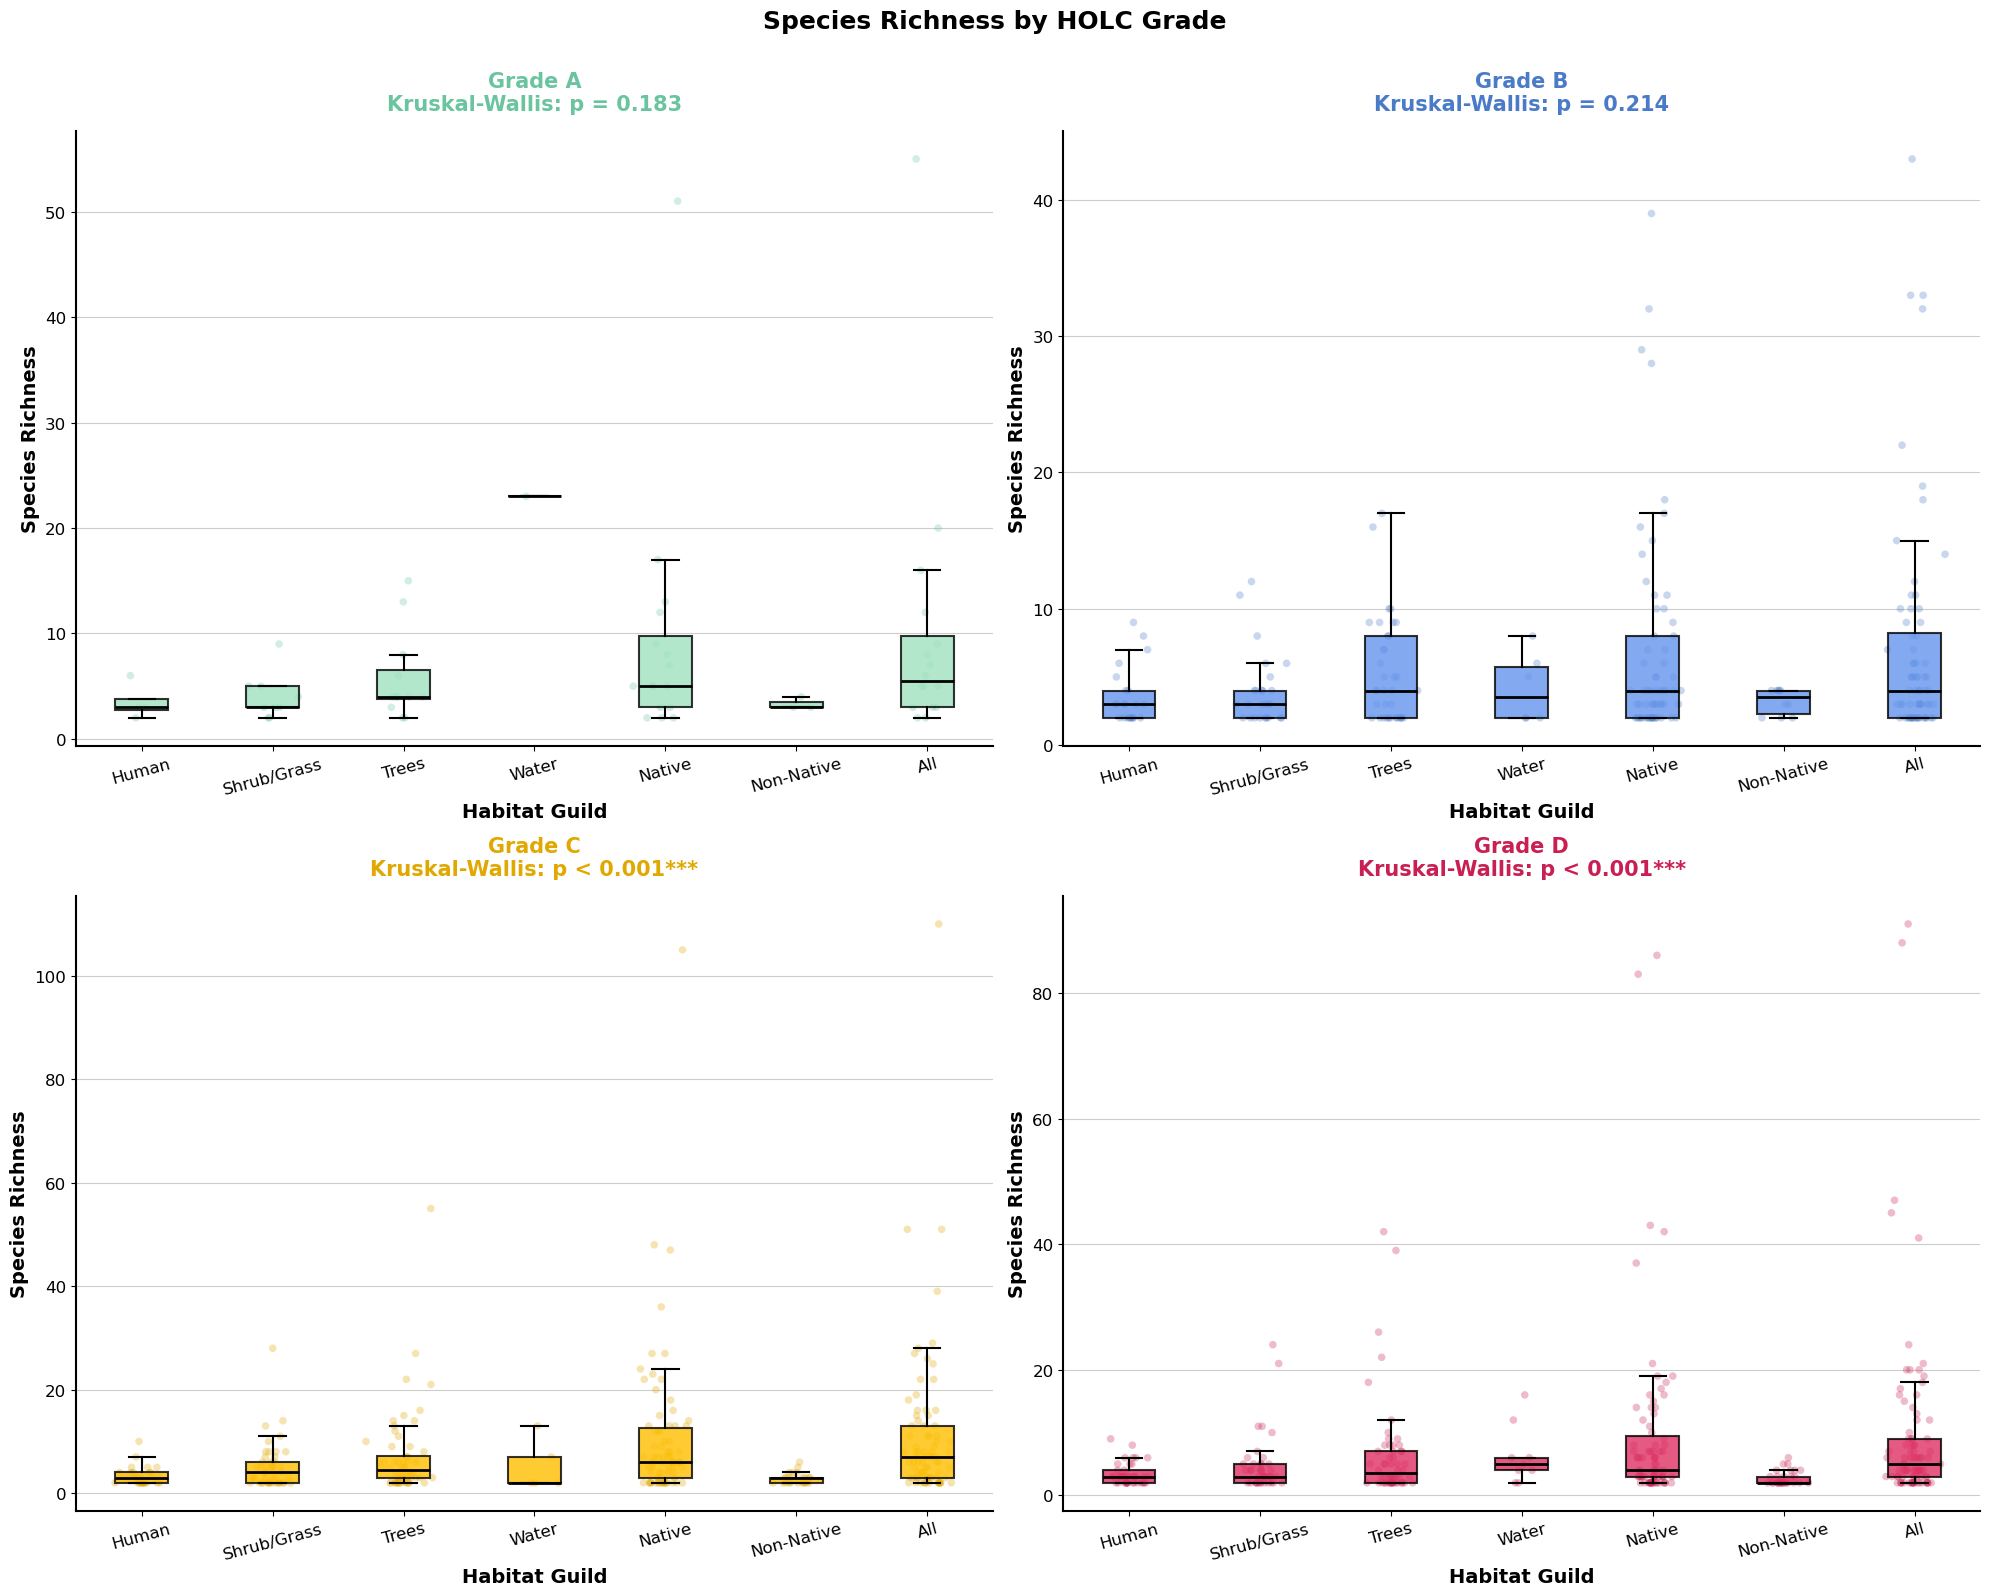

/tmp/ipykernel_168089/3682278372.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/3682278372.py:234: MatplotlibDepre


HABITAT: Human
Kruskal-Wallis: H=0.130, p=9.8803e-01
  Grade A: n=4, median=3.00
  Grade B: n=22, median=3.00
  Grade C: n=36, median=3.00
  Grade D: n=40, median=3.00

HABITAT: Shrub/Grass
Kruskal-Wallis: H=0.838, p=8.4047e-01
  Grade A: n=9, median=3.00
  Grade B: n=26, median=3.00
  Grade C: n=47, median=4.00
  Grade D: n=41, median=3.00

HABITAT: Trees
Kruskal-Wallis: H=1.223, p=7.4741e-01
  Grade A: n=12, median=4.00
  Grade B: n=36, median=4.00
  Grade C: n=60, median=4.50
  Grade D: n=56, median=3.50

HABITAT: Water
Kruskal-Wallis: H=3.581, p=3.1041e-01
  Grade A: n=1, median=23.00
  Grade B: n=6, median=3.50
  Grade C: n=5, median=2.00
  Grade D: n=9, median=5.00

HABITAT: Native
Kruskal-Wallis: H=5.018, p=1.7049e-01
  Grade A: n=16, median=5.00
  Grade B: n=63, median=4.00
  Grade C: n=75, median=6.00
  Grade D: n=79, median=4.00

HABITAT: Non-Native
Kruskal-Wallis: H=3.874, p=2.7540e-01
  Grade A: n=3, median=3.00
  Grade B: n=10, median=3.50
  Grade C: n=24, median=3.00
  G

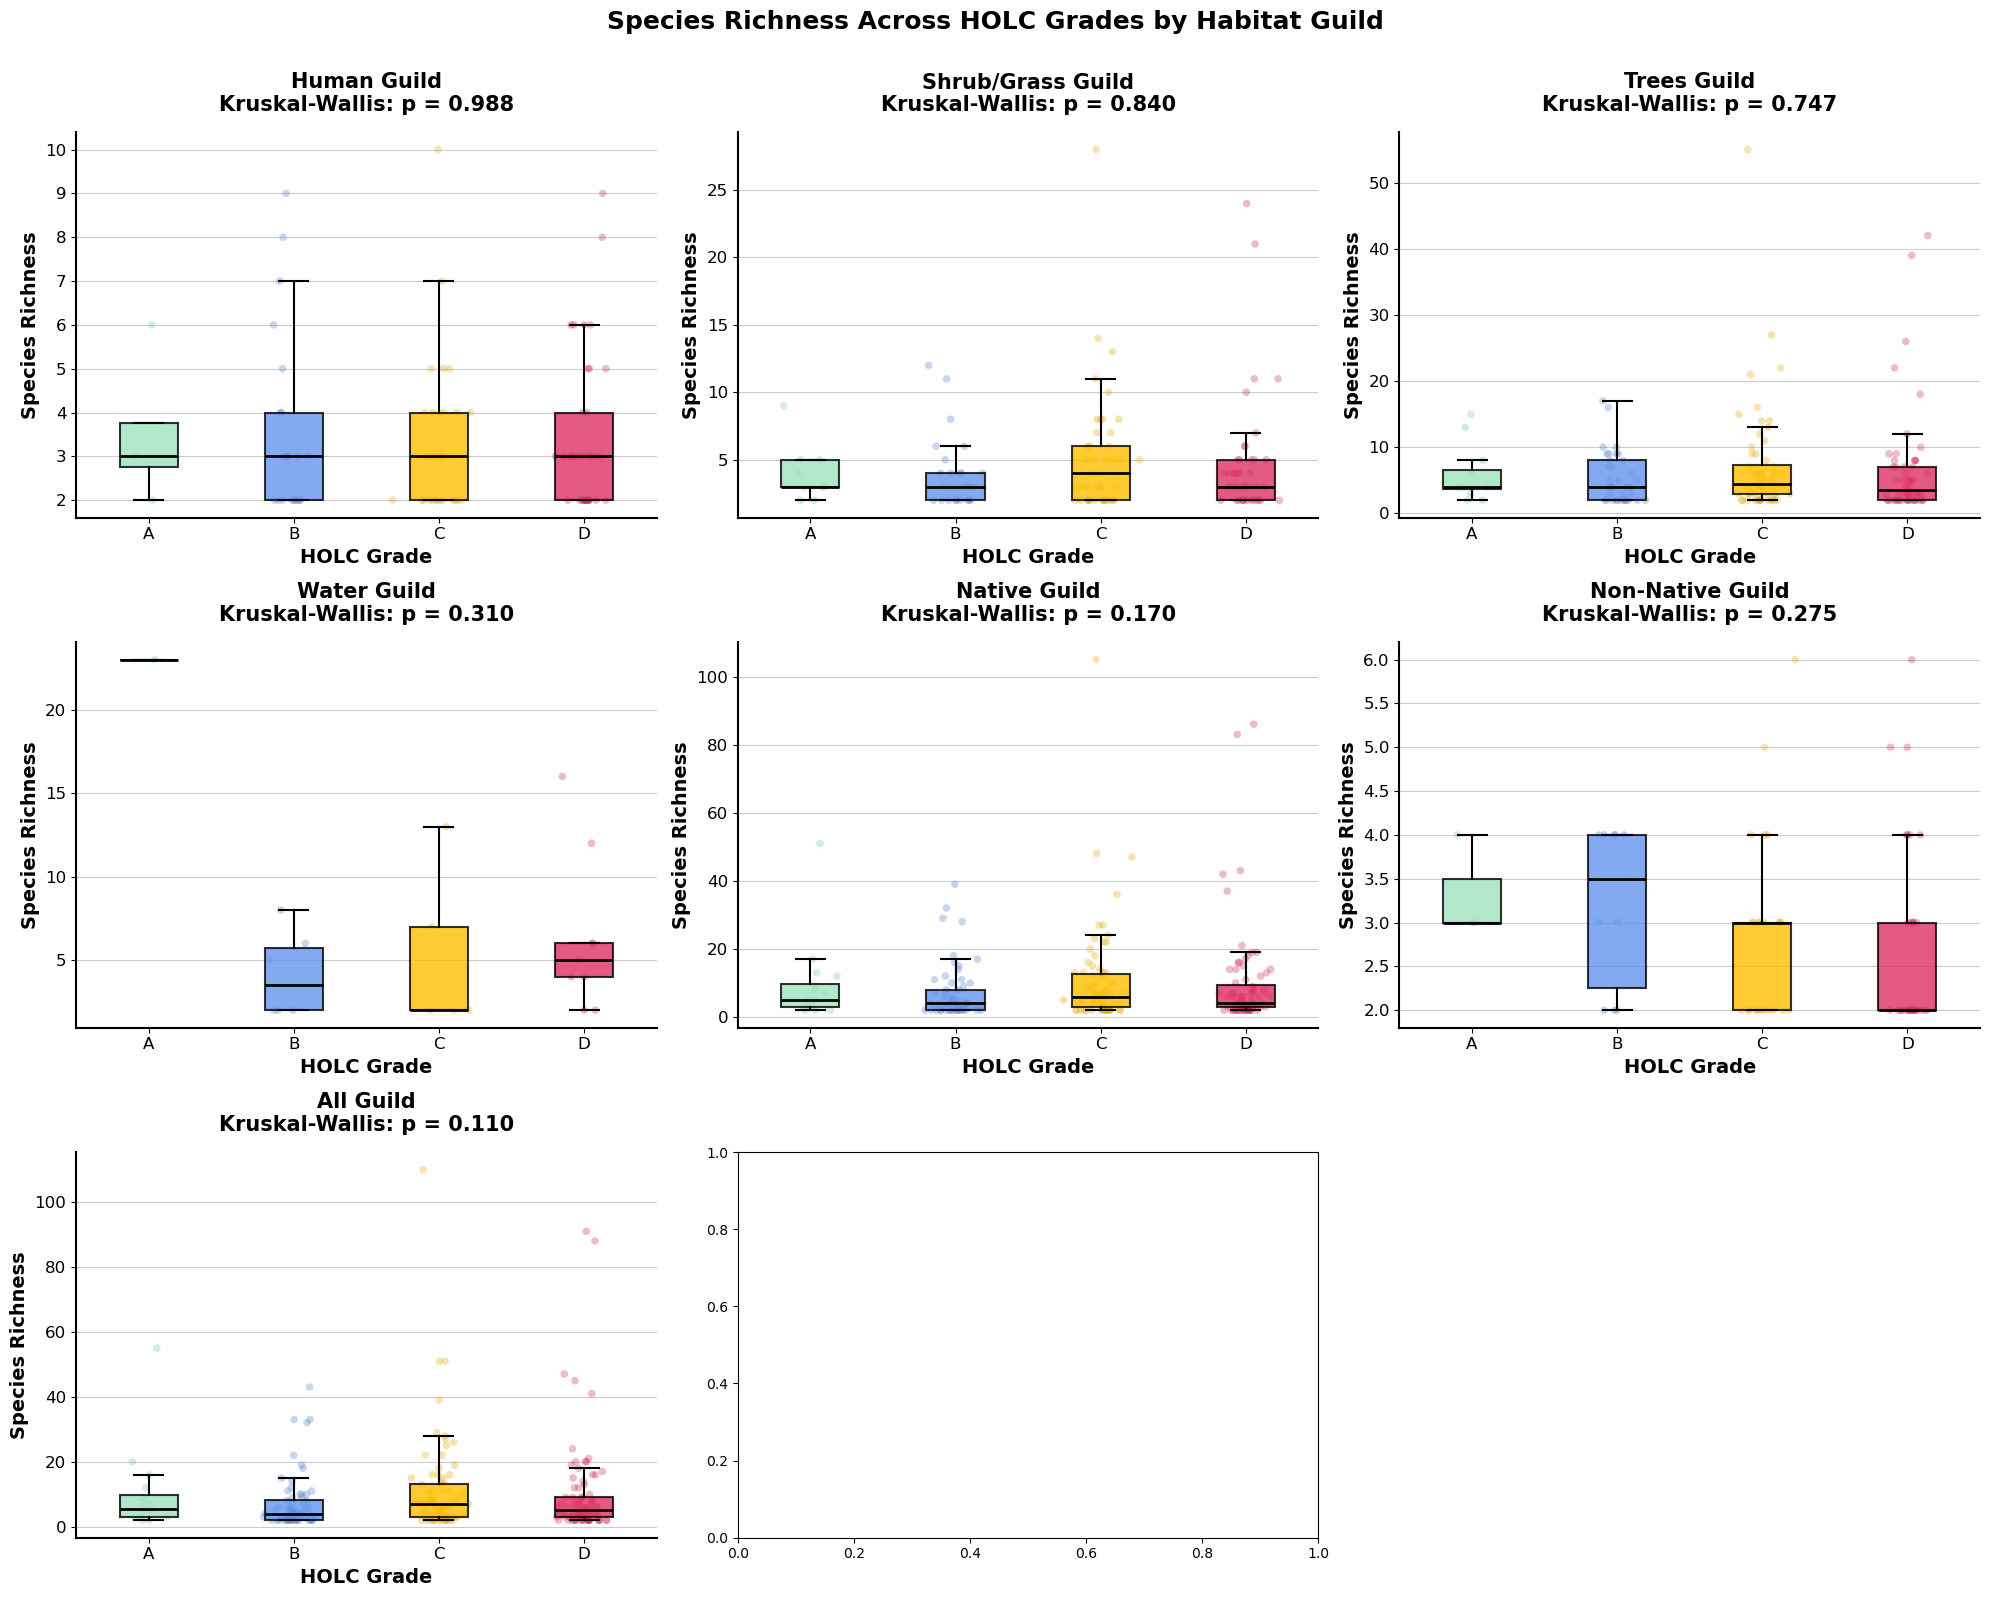

In [ ]:
# ============================================================
# USAGE
# ============================================================

# Load data
inext_human = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_human_reshape_2026_04_26.csv")
inext_shrubgrass = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_shrubgrass_reshape_2026_04_26.csv")
inext_trees = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_trees_reshape_2026_04_26.csv")
inext_water = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_water_reshape_2026_04_26.csv")
inext_native = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_native_reshape_2026_04_26.csv")
inext_nonnative = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_nonnative_reshape_2026_04_26.csv")
inext_all = pd.read_csv("./data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv")


# Extract grade from Assemblage column (last character)
def extract_grade(assemblage):
    """Extract the last character from assemblage string as grade"""
    return str(assemblage)[-1]

# Assuming box_data is a DataFrame
inext_human['grade'] = inext_human['Assemblage'].apply(extract_grade)
inext_human['grade'] = inext_human['grade'].astype('category')

inext_shrubgrass['grade'] = inext_shrubgrass['Assemblage'].apply(extract_grade)
inext_shrubgrass['grade'] = inext_shrubgrass['grade'].astype('category')


inext_trees['grade'] = inext_trees['Assemblage'].apply(extract_grade)
inext_trees['grade'] = inext_trees['grade'].astype('category')


inext_water['grade'] = inext_water['Assemblage'].apply(extract_grade)
inext_water['grade'] = inext_water['grade'].astype('category')

inext_native['grade'] = inext_native['Assemblage'].apply(extract_grade)
inext_native['grade'] = inext_native['grade'].astype('category')

inext_nonnative['grade'] = inext_nonnative['Assemblage'].apply(extract_grade)
inext_nonnative['grade'] = inext_nonnative['grade'].astype('category')

inext_all['grade'] = inext_all['Assemblage'].apply(extract_grade)
inext_all['grade'] = inext_all['grade'].astype('category')

# OPTION 1: Each graph = one GRADE, x-axis = habitats
# (All boxes in graph A are green, all in B are blue, etc.)
fig1 = create_guild_boxplots_by_grade(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/richness_guilds_by_grade_2026_04_26.png", log_transform=False
)

# OPTION 2: Each graph = one HABITAT, x-axis = grades  
# (Boxes colored by grade: A=green, B=blue, C=yellow, D=pink)
fig2 = create_guild_boxplots_by_habitat(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/richness_guilds_by_habitat_2026_04_26.png", log_transform=False
)

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from scikit_posthocs import posthoc_dunn

def create_guild_boxplots_by_grade(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Create a 2x2 grid of boxplots showing habitat guilds within each HOLC grade
    Each subplot represents one grade (A, B, C, D)
    X-axis: habitat type (Human, Shrub/Grass, Trees, Water)
    Y-axis: shannons Estimator
    """
    
    # Filter for shannons richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Shannon diversity'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Shannon diversity'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Shannon diversity'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Shannon diversity'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Shannon diversity'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Shannon diversity'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Shannon diversity'].copy(),
    }
    
    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Shannons (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Shannons'

    # Define colors matching your PCA (lighter fill, darker points)
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create 2x2 grid (or 4x1, depending on your preference)
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))  # 2x2 grid
    axes = axes.flatten()  # Flatten to 1D array for easy indexing
    
    for idx, grade in enumerate(grades):
        ax = axes[idx]
        
        # Prepare data for this grade across all habitats
        data_for_boxplot = []
        labels_for_boxplot = []
        
        for habitat in habitats:
            df = datasets[habitat]
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col instead of 'Estimator'
            data_for_boxplot.append(grade_data)
            labels_for_boxplot.append(habitat)
        
        # Add jittered points FIRST
        for i, habitat in enumerate(habitats):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(habitats)),
            labels=labels_for_boxplot,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color ALL boxes with the grade's color
        for patch in box_parts['boxes']:
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test for this grade
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('Habitat Guild', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"Grade {grade}\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15,
                    color=grade_colors[grade]['point'])
        ax.tick_params(axis='both', labelsize=12)
        ax.tick_params(axis='x', rotation=15)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray')
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats for this grade
        print(f"\n{'='*60}")
        print(f"GRADE {grade}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        # Calculate sample sizes
        for habitat, data in zip(habitats, data_for_boxplot):
            if len(data) > 0:
                print(f"  {habitat}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  {habitat}: n=0, median=N/A")
    
    # Overall title
    fig.suptitle('Shannons Diversity by HOLC Grade', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n✓ Figure saved to: {output_path}")
    plt.show()
    
    return fig


def create_guild_boxplots_by_habitat(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Alternative layout: Grid where each subplot is a HABITAT
    X-axis: HOLC grades (A, B, C, D)
    Y-axis: Species Diversity Estimator
    Each box colored by grade
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Shannon diversity'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Shannon diversity'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Shannon diversity'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Shannon diversity'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Shannon diversity'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Shannon diversity'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Shannon diversity'].copy(),
    }

    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Shannons Diversity (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Shannons Richness'
    
    # Define colors
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create grid for 7 habitats (e.g., 3x3 or 4x2)
    fig, axes = plt.subplots(3, 3, figsize=(20, 16))  # 3x3 grid for 7 habitats
    axes = axes.flatten()
    
    for idx, habitat in enumerate(habitats):
        ax = axes[idx]
        df = datasets[habitat]
        
        # Prepare data for this habitat across all grades
        data_for_boxplot = []
        
        for grade in grades:
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col
            data_for_boxplot.append(grade_data)
        
        # Add jittered points FIRST (colored by grade)
        for i, grade in enumerate(grades):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(grades)),
            labels=grades,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color boxes by grade
        for patch, grade in zip(box_parts['boxes'], grades):
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('HOLC Grade', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"{habitat} Guild\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15)
        ax.tick_params(axis='both', labelsize=12)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray', zorder=0)
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats
        print(f"\n{'='*60}")
        print(f"HABITAT: {habitat}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        for grade, data in zip(grades, data_for_boxplot):
            if len(data) > 0:
                print(f"  Grade {grade}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  Grade {grade}: n=0, median=N/A")
    

 # Hide empty subplot
    if len(habitats) < len(axes):
        axes[-1].set_visible(False)
    
    # Overall title
    fig.suptitle('Shannons Across HOLC Grades by Habitat Guild', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300)


/tmp/ipykernel_168089/208330740.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(



GRADE A
Kruskal-Wallis: H=5.848, p=4.4045e-01
  Human: n=4, median=2.59
  Shrub/Grass: n=9, median=3.12
  Trees: n=12, median=3.38
  Water: n=1, median=7.36
  Native: n=16, median=4.52
  Non-Native: n=3, median=2.77
  All: n=16, median=4.52

GRADE B
Kruskal-Wallis: H=23.819, p=5.6386e-04
  Human: n=22, median=2.21
  Shrub/Grass: n=26, median=2.56
  Trees: n=36, median=3.72
  Water: n=6, median=1.74
  Native: n=63, median=3.20
  Non-Native: n=10, median=2.15
  All: n=68, median=3.32

GRADE C
Kruskal-Wallis: H=68.027, p=1.0374e-12
  Human: n=36, median=2.39
  Shrub/Grass: n=47, median=3.44
  Trees: n=60, median=4.04
  Water: n=5, median=1.99
  Native: n=75, median=5.36
  Non-Native: n=24, median=2.03
  All: n=80, median=5.40

GRADE D
Kruskal-Wallis: H=58.895, p=7.5465e-11
  Human: n=40, median=2.32
  Shrub/Grass: n=41, median=2.85
  Trees: n=56, median=3.04
  Water: n=9, median=3.28
  Native: n=79, median=3.97
  Non-Native: n=30, median=2.00
  All: n=89, median=4.34

✓ Figure saved to: 

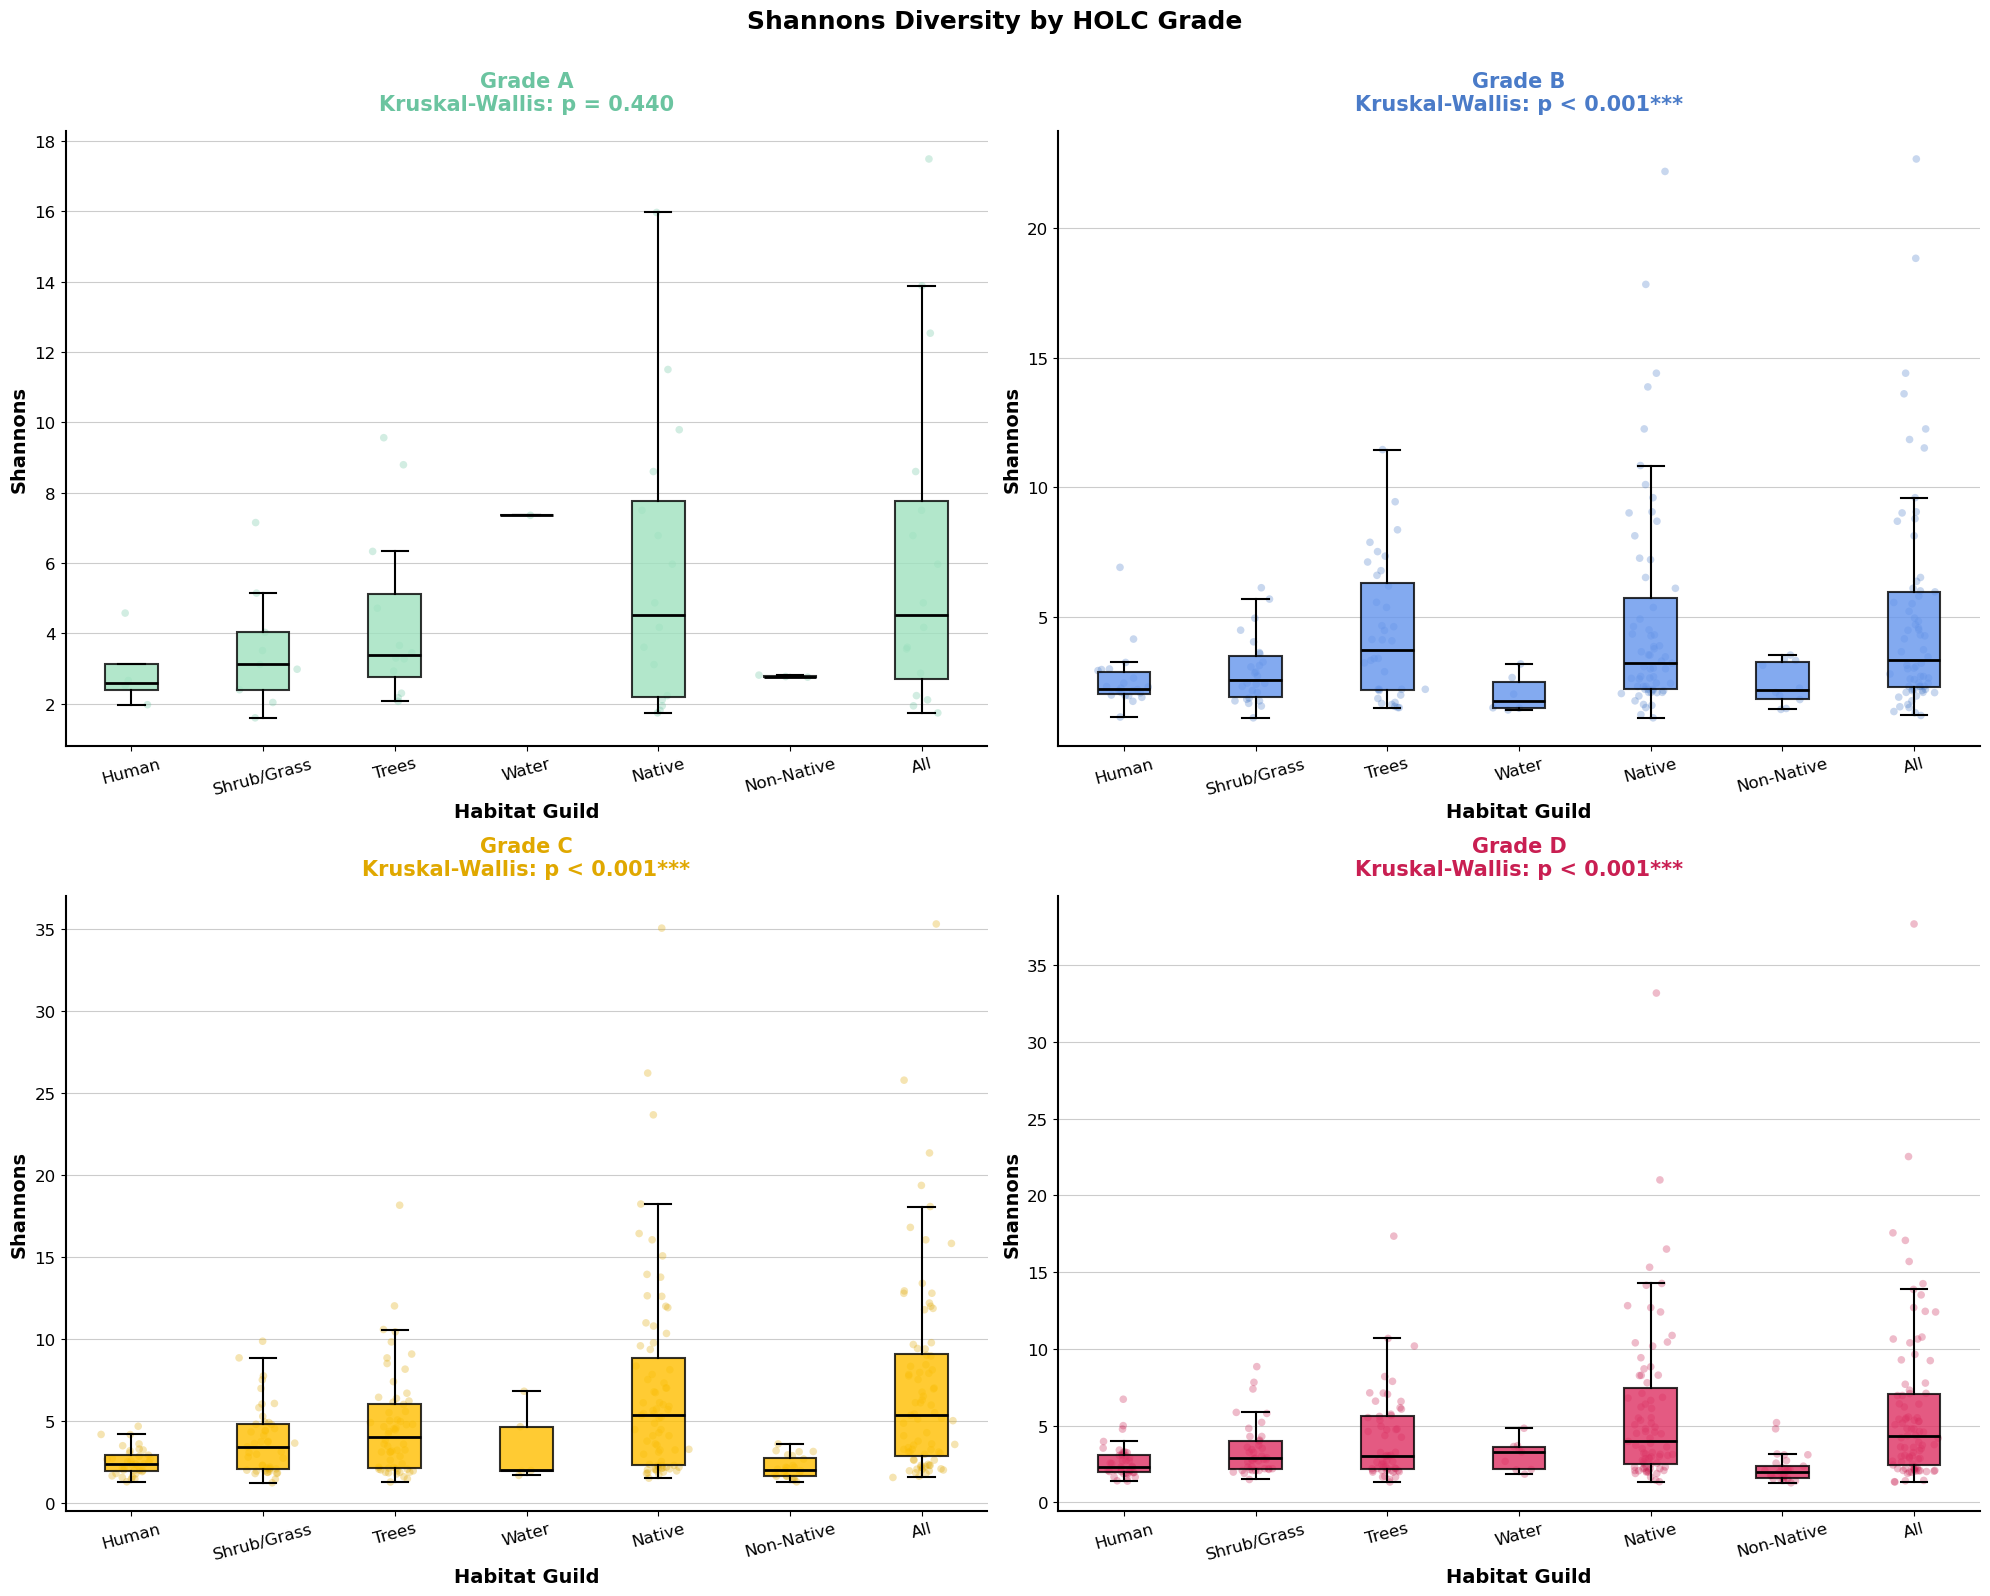

/tmp/ipykernel_168089/208330740.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/208330740.py:234: MatplotlibDeprecatio


HABITAT: Human
Kruskal-Wallis: H=0.734, p=8.6509e-01
  Grade A: n=4, median=2.59
  Grade B: n=22, median=2.21
  Grade C: n=36, median=2.39
  Grade D: n=40, median=2.32

HABITAT: Shrub/Grass
Kruskal-Wallis: H=3.125, p=3.7274e-01
  Grade A: n=9, median=3.12
  Grade B: n=26, median=2.56
  Grade C: n=47, median=3.44
  Grade D: n=41, median=2.85

HABITAT: Trees
Kruskal-Wallis: H=0.833, p=8.4162e-01
  Grade A: n=12, median=3.38
  Grade B: n=36, median=3.72
  Grade C: n=60, median=4.04
  Grade D: n=56, median=3.04

HABITAT: Water
Kruskal-Wallis: H=6.926, p=7.4281e-02
  Grade A: n=1, median=7.36
  Grade B: n=6, median=1.74
  Grade C: n=5, median=1.99
  Grade D: n=9, median=3.28

HABITAT: Native
Kruskal-Wallis: H=5.833, p=1.2002e-01
  Grade A: n=16, median=4.52
  Grade B: n=63, median=3.20
  Grade C: n=75, median=5.36
  Grade D: n=79, median=3.97

HABITAT: Non-Native
Kruskal-Wallis: H=3.535, p=3.1627e-01
  Grade A: n=3, median=2.77
  Grade B: n=10, median=2.15
  Grade C: n=24, median=2.03
  Gr

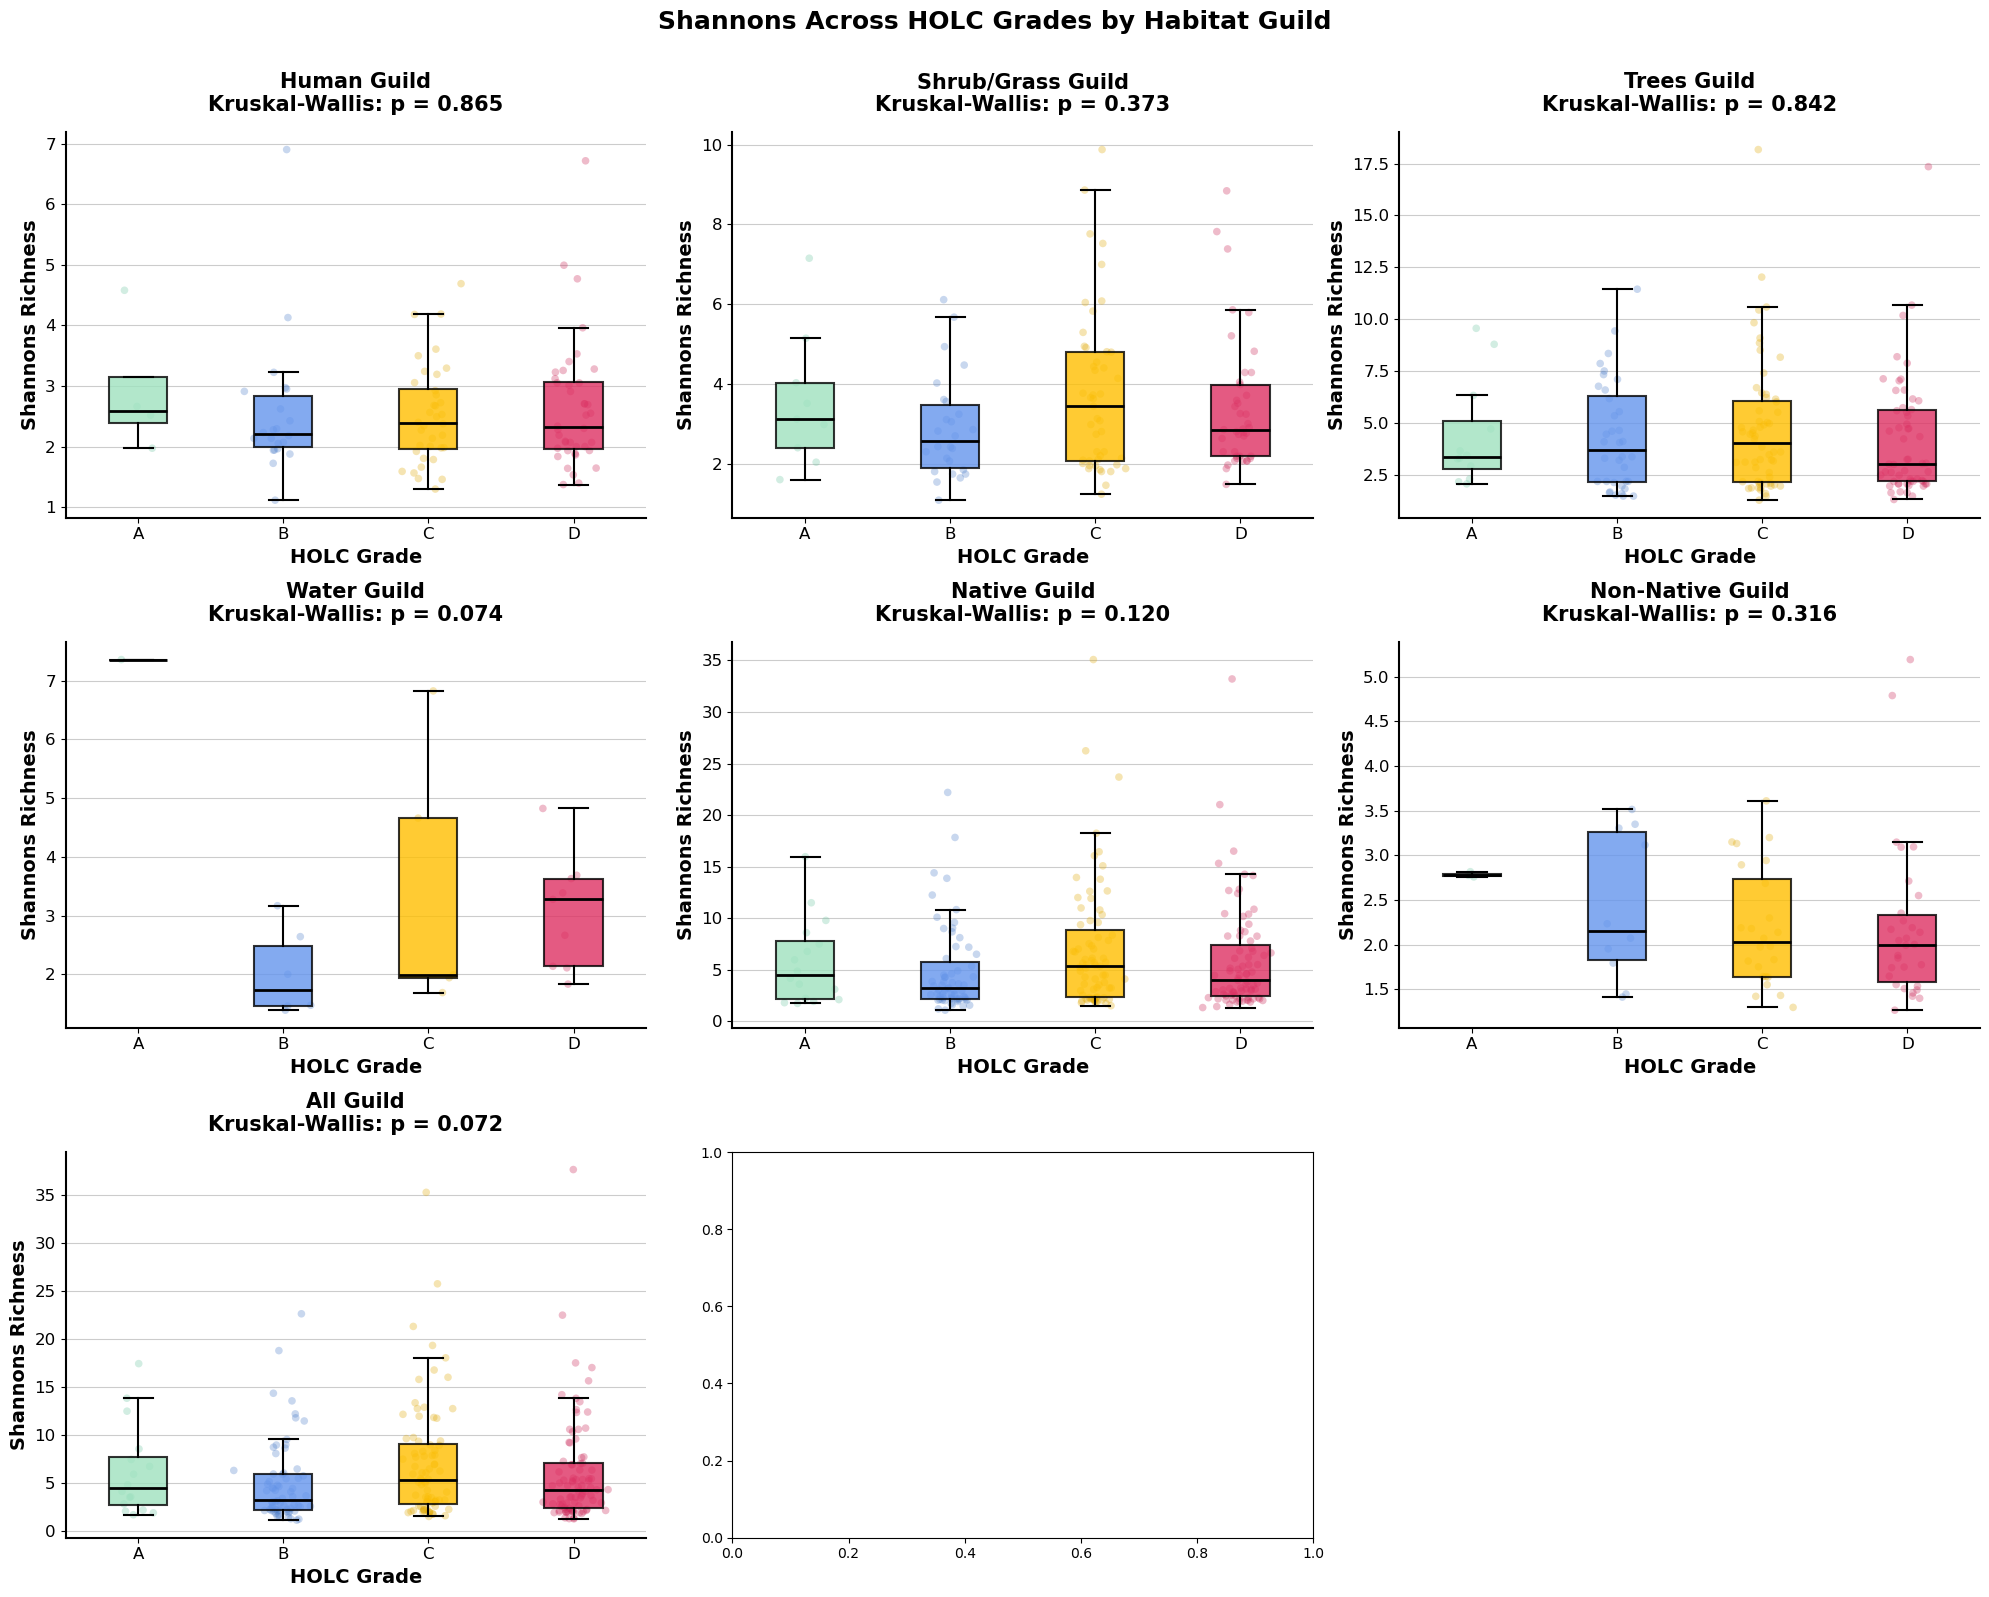

In [ ]:
#Now do for shannons 
# ============================================================
# USAGE
# ============================================================

# Load data
inext_human = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_human_reshape_2026_04_26.csv")
inext_shrubgrass = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_shrubgrass_reshape_2026_04_26.csv")
inext_trees = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_trees_reshape_2026_04_26.csv")
inext_water = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_water_reshape_2026_04_26.csv")
inext_native = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_native_reshape_2026_04_26.csv")
inext_nonnative = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_nonnative_reshape_2026_04_26.csv")
inext_all = pd.read_csv("./data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv")


# Extract grade from Assemblage column (last character)
def extract_grade(assemblage):
    """Extract the last character from assemblage string as grade"""
    return str(assemblage)[-1]

# Assuming box_data is a DataFrame
inext_human['grade'] = inext_human['Assemblage'].apply(extract_grade)
inext_human['grade'] = inext_human['grade'].astype('category')

inext_shrubgrass['grade'] = inext_shrubgrass['Assemblage'].apply(extract_grade)
inext_shrubgrass['grade'] = inext_shrubgrass['grade'].astype('category')


inext_trees['grade'] = inext_trees['Assemblage'].apply(extract_grade)
inext_trees['grade'] = inext_trees['grade'].astype('category')


inext_water['grade'] = inext_water['Assemblage'].apply(extract_grade)
inext_water['grade'] = inext_water['grade'].astype('category')

inext_native['grade'] = inext_native['Assemblage'].apply(extract_grade)
inext_native['grade'] = inext_native['grade'].astype('category')

inext_nonnative['grade'] = inext_nonnative['Assemblage'].apply(extract_grade)
inext_nonnative['grade'] = inext_nonnative['grade'].astype('category')

inext_all['grade'] = inext_all['Assemblage'].apply(extract_grade)
inext_all['grade'] = inext_all['grade'].astype('category')

# OPTION 1: Each graph = one GRADE, x-axis = habitats
# (All boxes in graph A are green, all in B are blue, etc.)
fig1 = create_guild_boxplots_by_grade(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/shannons_guilds_by_grade_2026_04_26.png", log_transform=False
)

# OPTION 2: Each graph = one HABITAT, x-axis = grades  
# (Boxes colored by grade: A=green, B=blue, C=yellow, D=pink)
fig2 = create_guild_boxplots_by_habitat(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/shannons_guilds_by_habitat_2026_04_26.png", log_transform=False
)

In [ ]:
#Now for Simpsons 

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from scikit_posthocs import posthoc_dunn

def create_guild_boxplots_by_grade(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Create a 2x2 grid of boxplots showing habitat guilds within each HOLC grade
    Each subplot represents one grade (A, B, C, D)
    X-axis: habitat type (Human, Shrub/Grass, Trees, Water)
    Y-axis: Simpsons Estimator
    """
    
    # Filter for shannons richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Simpson diversity'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Simpson diversity'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Simpson diversity'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Simpson diversity'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Simpson diversity'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Simpson diversity'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Simpson diversity'].copy(),
    }
    
    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Simpsons (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Simpsons'

    # Define colors matching your PCA (lighter fill, darker points)
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create 2x2 grid (or 4x1, depending on your preference)
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))  # 2x2 grid
    axes = axes.flatten()  # Flatten to 1D array for easy indexing
    
    for idx, grade in enumerate(grades):
        ax = axes[idx]
        
        # Prepare data for this grade across all habitats
        data_for_boxplot = []
        labels_for_boxplot = []
        
        for habitat in habitats:
            df = datasets[habitat]
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col instead of 'Estimator'
            data_for_boxplot.append(grade_data)
            labels_for_boxplot.append(habitat)
        
        # Add jittered points FIRST
        for i, habitat in enumerate(habitats):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(habitats)),
            labels=labels_for_boxplot,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color ALL boxes with the grade's color
        for patch in box_parts['boxes']:
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test for this grade
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('Habitat Guild', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"Grade {grade}\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15,
                    color=grade_colors[grade]['point'])
        ax.tick_params(axis='both', labelsize=12)
        ax.tick_params(axis='x', rotation=15)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray')
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats for this grade
        print(f"\n{'='*60}")
        print(f"GRADE {grade}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        # Calculate sample sizes
        for habitat, data in zip(habitats, data_for_boxplot):
            if len(data) > 0:
                print(f"  {habitat}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  {habitat}: n=0, median=N/A")
    
    # Overall title
    fig.suptitle('Shannons Diversity by HOLC Grade', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n✓ Figure saved to: {output_path}")
    plt.show()
    
    return fig


def create_guild_boxplots_by_habitat(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Alternative layout: Grid where each subplot is a HABITAT
    X-axis: HOLC grades (A, B, C, D)
    Y-axis: Species Diversity Estimator
    Each box colored by grade
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Simpson diversity'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Simpson diversity'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Simpson diversity'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Simpson diversity'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Simpson diversity'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Simpson diversity'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Simpson diversity'].copy(),
    }

    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            # Add small constant to avoid log(0), then take log10
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Simpson Diversity (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Simpsons'
    
    # Define colors
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIX: Create grid for 7 habitats (e.g., 3x3 or 4x2)
    fig, axes = plt.subplots(3, 3, figsize=(20, 16))  # 3x3 grid for 7 habitats
    axes = axes.flatten()
    
    for idx, habitat in enumerate(habitats):
        ax = axes[idx]
        df = datasets[habitat]
        
        # Prepare data for this habitat across all grades
        data_for_boxplot = []
        
        for grade in grades:
            grade_data = df[df['grade'] == grade][value_col].values  # Use value_col
            data_for_boxplot.append(grade_data)
        
        # Add jittered points FIRST (colored by grade)
        for i, grade in enumerate(grades):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(grades)),
            labels=grades,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color boxes by grade
        for patch, grade in zip(box_parts['boxes'], grades):
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('HOLC Grade', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"{habitat} Guild\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15)
        ax.tick_params(axis='both', labelsize=12)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray', zorder=0)
        ax.set_axisbelow(True)
        
        # Log scale only if log_transform is True
        if log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats
        print(f"\n{'='*60}")
        print(f"HABITAT: {habitat}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        for grade, data in zip(grades, data_for_boxplot):
            if len(data) > 0:
                print(f"  Grade {grade}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  Grade {grade}: n=0, median=N/A")
    

 # Hide empty subplot
    if len(habitats) < len(axes):
        axes[-1].set_visible(False)
    
    # Overall title
    fig.suptitle('Simpsons Diversity Across HOLC Grades by Habitat Guild', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300)


/tmp/ipykernel_168089/2462337715.py:76: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:76: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:76: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:76: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(



GRADE A
Kruskal-Wallis: H=3.745, p=7.1109e-01
  Human: n=4, median=2.28
  Shrub/Grass: n=9, median=2.96
  Trees: n=12, median=2.95
  Water: n=1, median=4.07
  Native: n=16, median=4.27
  Non-Native: n=3, median=2.54
  All: n=16, median=4.27

GRADE B
Kruskal-Wallis: H=31.399, p=2.1272e-05
  Human: n=22, median=1.95
  Shrub/Grass: n=26, median=2.29
  Trees: n=36, median=3.50
  Water: n=6, median=1.56
  Native: n=63, median=2.96
  Non-Native: n=10, median=1.95
  All: n=68, median=3.17

GRADE C
Kruskal-Wallis: H=67.367, p=1.4156e-12
  Human: n=36, median=2.06
  Shrub/Grass: n=47, median=3.00
  Trees: n=60, median=3.50
  Water: n=5, median=1.98
  Native: n=75, median=4.64
  Non-Native: n=24, median=1.87
  All: n=80, median=4.27

GRADE D
Kruskal-Wallis: H=62.118, p=1.6689e-11
  Human: n=40, median=2.28
  Shrub/Grass: n=41, median=2.64
  Trees: n=56, median=3.00
  Water: n=9, median=2.66
  Native: n=79, median=3.50
  Non-Native: n=30, median=1.84
  All: n=89, median=3.50

✓ Figure saved to: 

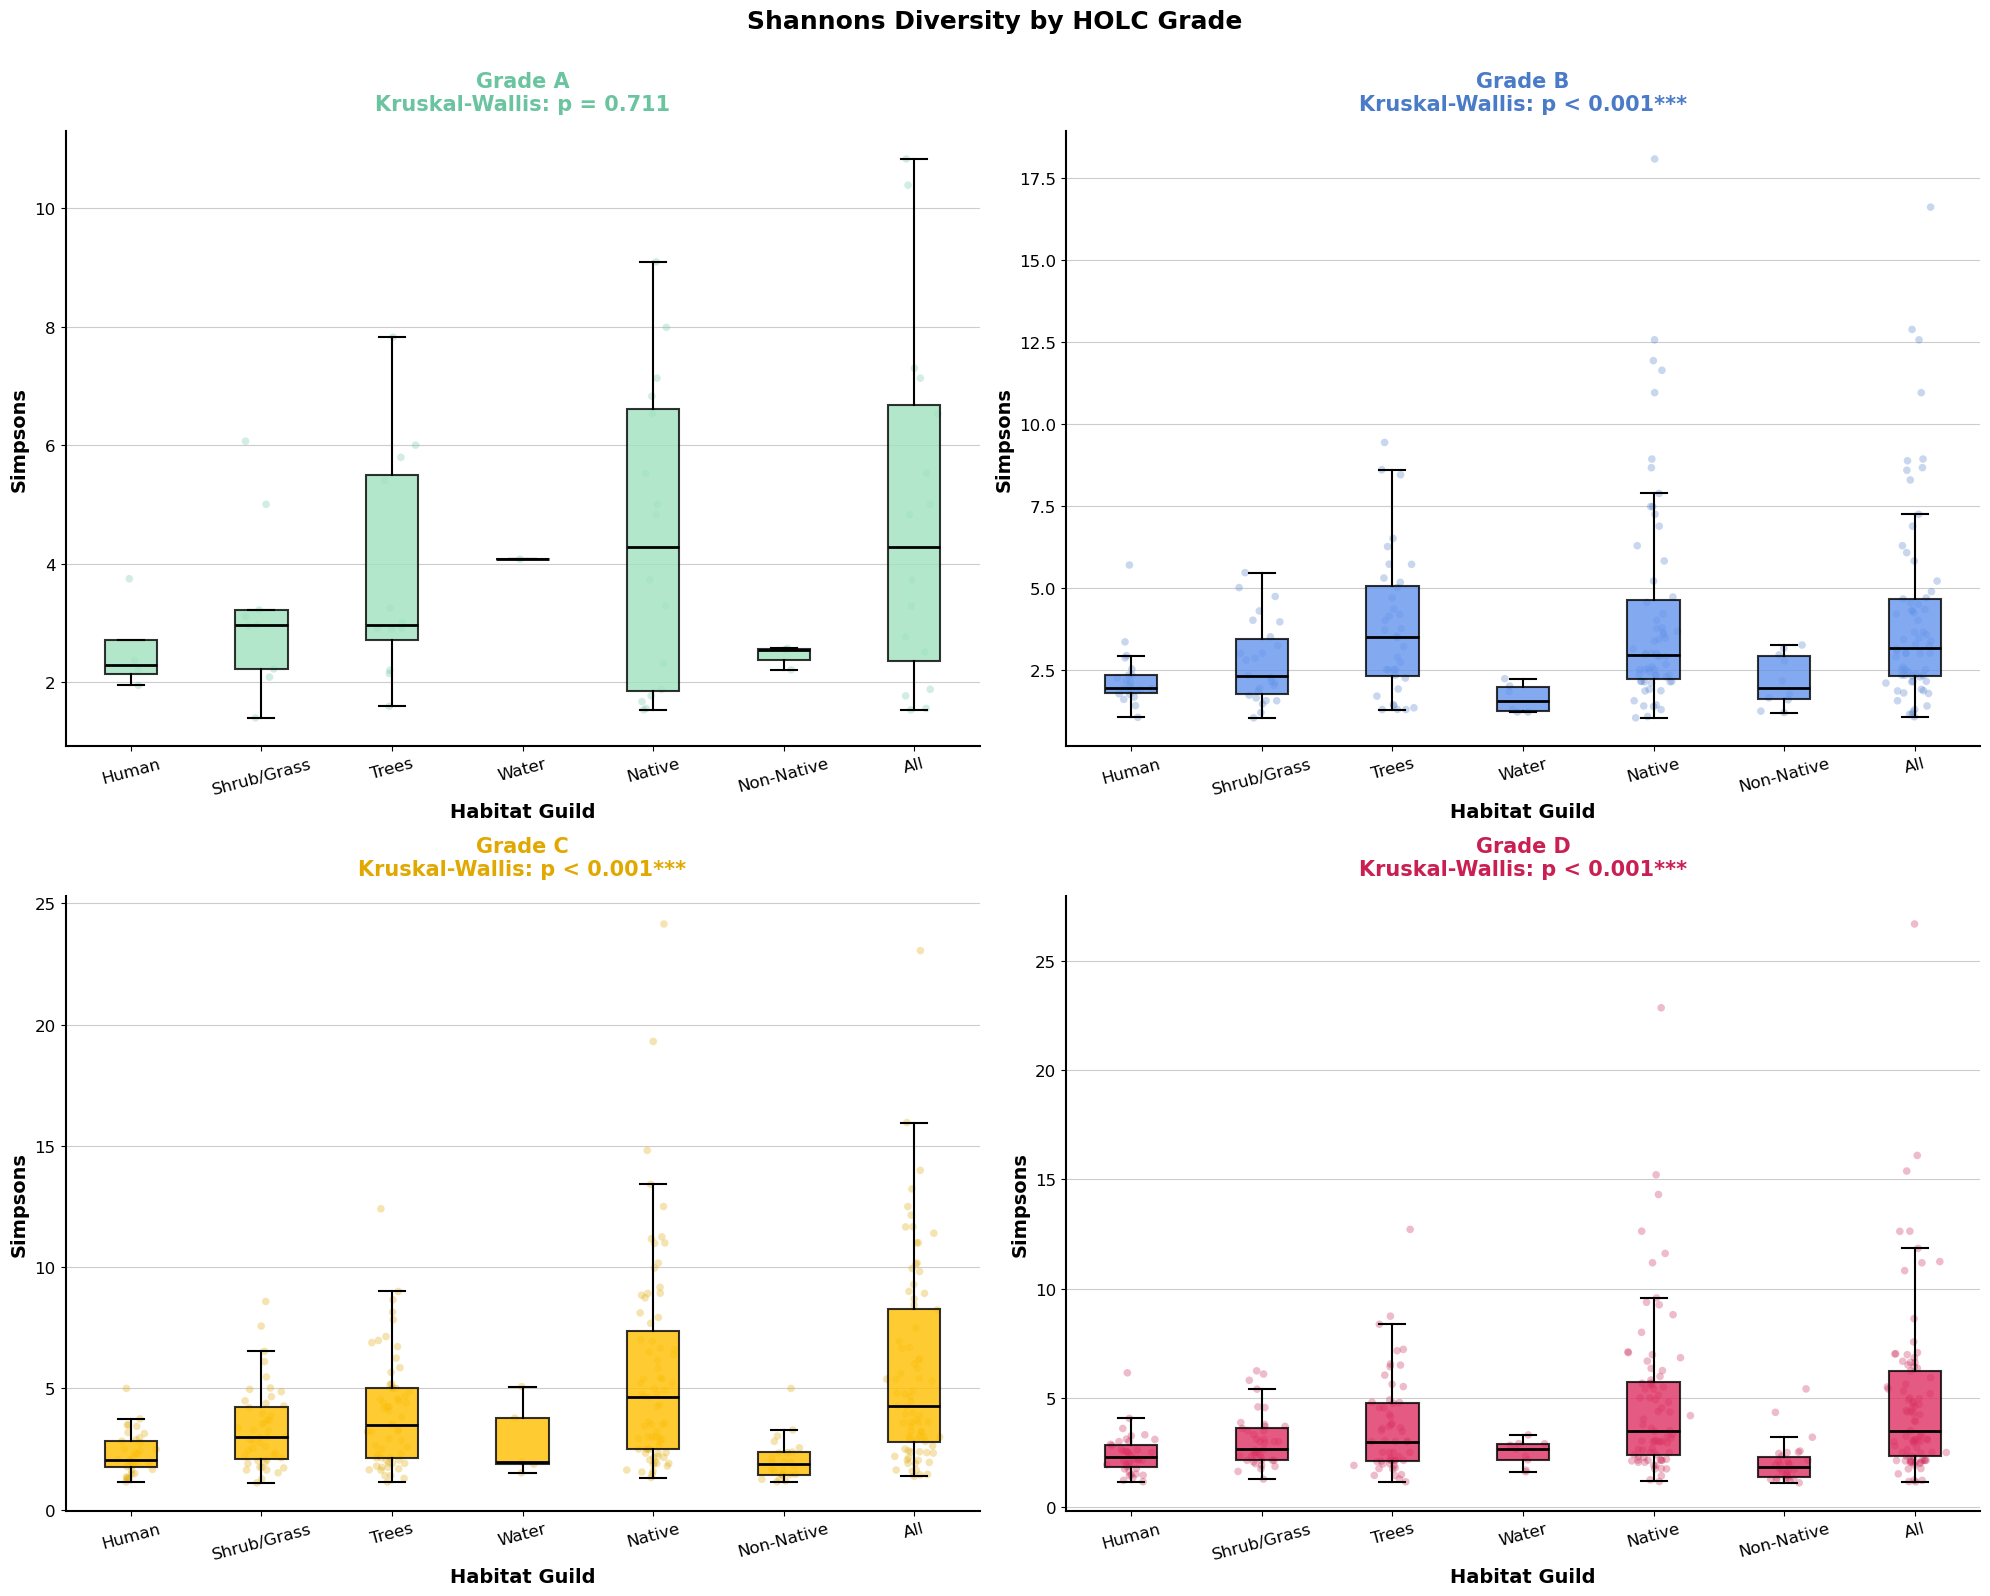

/tmp/ipykernel_168089/2462337715.py:236: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:236: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:236: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:236: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_parts = ax.boxplot(
/tmp/ipykernel_168089/2462337715.py:236: MatplotlibDepre


HABITAT: Human
Kruskal-Wallis: H=2.111, p=5.4971e-01
  Grade A: n=4, median=2.28
  Grade B: n=22, median=1.95
  Grade C: n=36, median=2.06
  Grade D: n=40, median=2.28

HABITAT: Shrub/Grass
Kruskal-Wallis: H=3.199, p=3.6190e-01
  Grade A: n=9, median=2.96
  Grade B: n=26, median=2.29
  Grade C: n=47, median=3.00
  Grade D: n=41, median=2.64

HABITAT: Trees
Kruskal-Wallis: H=0.538, p=9.1049e-01
  Grade A: n=12, median=2.95
  Grade B: n=36, median=3.50
  Grade C: n=60, median=3.50
  Grade D: n=56, median=3.00

HABITAT: Water
Kruskal-Wallis: H=7.190, p=6.6085e-02
  Grade A: n=1, median=4.07
  Grade B: n=6, median=1.56
  Grade C: n=5, median=1.98
  Grade D: n=9, median=2.66

HABITAT: Native
Kruskal-Wallis: H=5.760, p=1.2389e-01
  Grade A: n=16, median=4.27
  Grade B: n=63, median=2.96
  Grade C: n=75, median=4.64
  Grade D: n=79, median=3.50

HABITAT: Non-Native
Kruskal-Wallis: H=3.026, p=3.8767e-01
  Grade A: n=3, median=2.54
  Grade B: n=10, median=1.95
  Grade C: n=24, median=1.87
  Gr

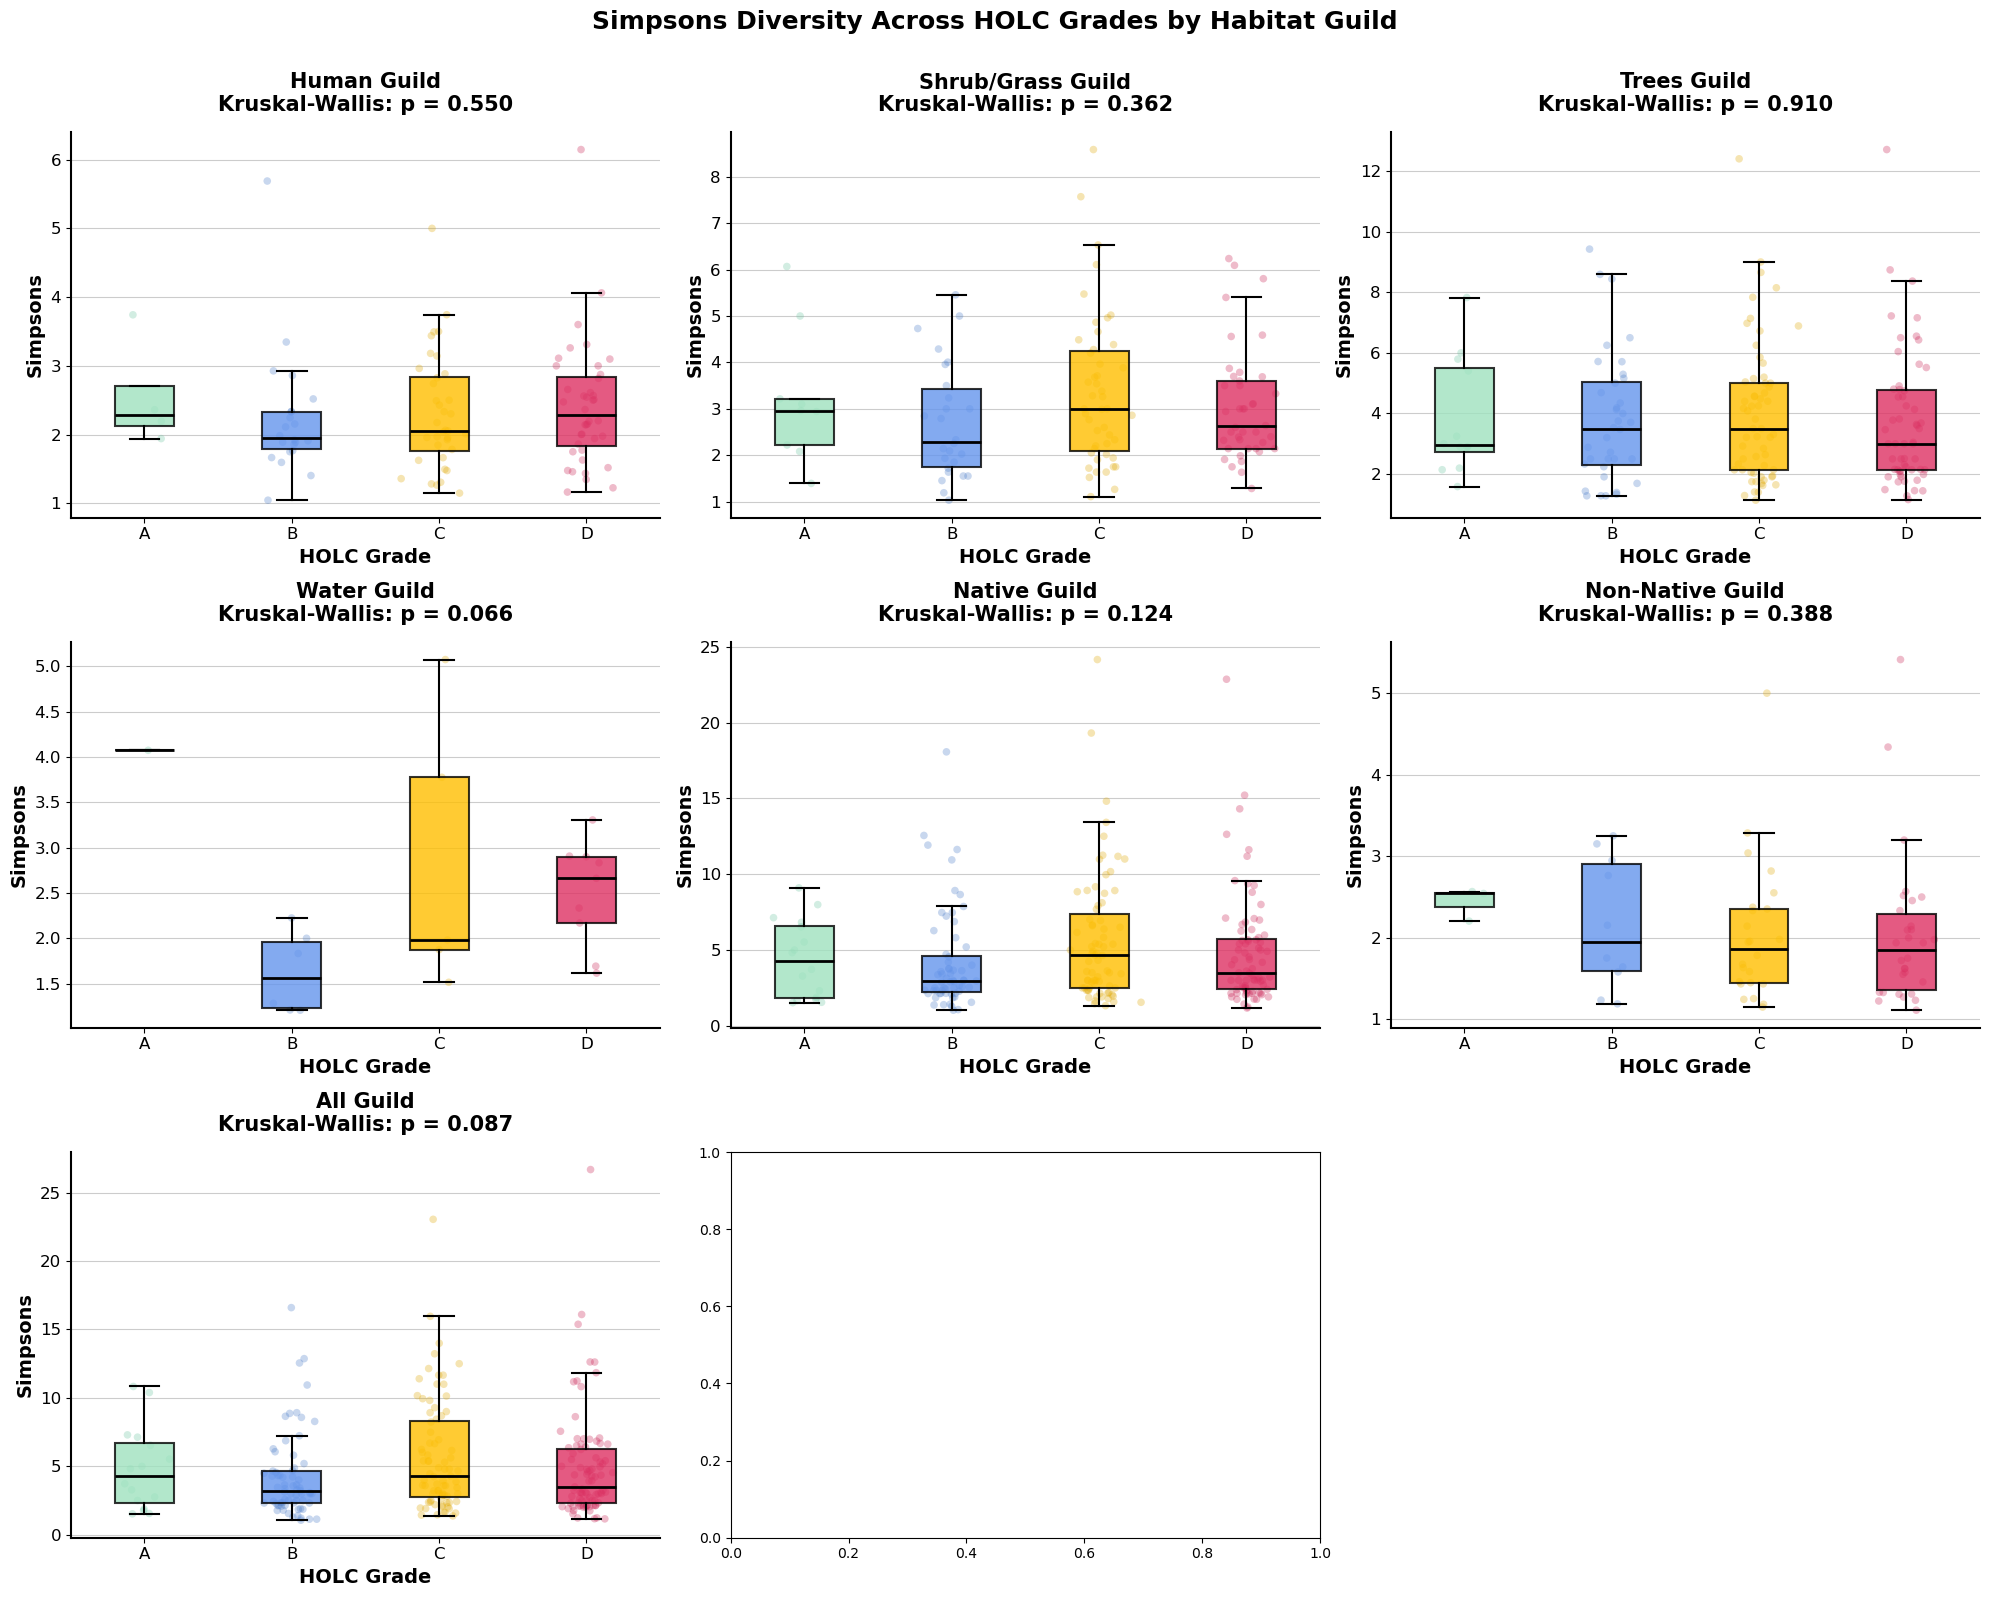

In [ ]:
#Usage for Simpsons 
# ============================================================
# USAGE
# ============================================================

# Load data
inext_human = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_human_reshape_2026_04_26.csv")
inext_shrubgrass = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_shrubgrass_reshape_2026_04_26.csv")
inext_trees = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_trees_reshape_2026_04_26.csv")
inext_water = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_water_reshape_2026_04_26.csv")
inext_native = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_native_reshape_2026_04_26.csv")
inext_nonnative = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_nonnative_reshape_2026_04_26.csv")
inext_all = pd.read_csv("./data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv")


# Extract grade from Assemblage column (last character)
def extract_grade(assemblage):
    """Extract the last character from assemblage string as grade"""
    return str(assemblage)[-1]

# Assuming box_data is a DataFrame
inext_human['grade'] = inext_human['Assemblage'].apply(extract_grade)
inext_human['grade'] = inext_human['grade'].astype('category')

inext_shrubgrass['grade'] = inext_shrubgrass['Assemblage'].apply(extract_grade)
inext_shrubgrass['grade'] = inext_shrubgrass['grade'].astype('category')


inext_trees['grade'] = inext_trees['Assemblage'].apply(extract_grade)
inext_trees['grade'] = inext_trees['grade'].astype('category')


inext_water['grade'] = inext_water['Assemblage'].apply(extract_grade)
inext_water['grade'] = inext_water['grade'].astype('category')

inext_native['grade'] = inext_native['Assemblage'].apply(extract_grade)
inext_native['grade'] = inext_native['grade'].astype('category')

inext_nonnative['grade'] = inext_nonnative['Assemblage'].apply(extract_grade)
inext_nonnative['grade'] = inext_nonnative['grade'].astype('category')

inext_all['grade'] = inext_all['Assemblage'].apply(extract_grade)
inext_all['grade'] = inext_all['grade'].astype('category')

# OPTION 1: Each graph = one GRADE, x-axis = habitats
# (All boxes in graph A are green, all in B are blue, etc.)
fig1 = create_guild_boxplots_by_grade(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/simpsons_guilds_by_grade_2026_04_26.png", log_transform=False
)

# OPTION 2: Each graph = one HABITAT, x-axis = grades  
# (Boxes colored by grade: A=green, B=blue, C=yellow, D=pink)
fig2 = create_guild_boxplots_by_habitat(
    inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, "../results_images/simpson_guilds_by_habitat_2026_04_26.png", log_transform=False
)

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from scikit_posthocs import posthoc_dunn

def create_guild_boxplots_by_grade(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Create a 2x4 grid of boxplots showing habitat guilds within each HOLC grade
    Each subplot represents one grade (A, B, C, D)
    X-axis: habitat type (Human, Shrub/Grass, Trees, Water, Native, Non-Native, All)
    Y-axis: Species Richness Estimator
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Species richness'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Species richness'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Species richness'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Species richness'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Species richness'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Species richness'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Species richness'].copy(),
    }
    
    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Species Richness (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Species Richness'

    # Define colors matching your PCA (lighter fill, darker points)
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIXED: Create 2x2 grid
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))
    axes = axes.flatten()
    
    for idx, grade in enumerate(grades):
        ax = axes[idx]
        
        # Prepare data for this grade across all habitats
        data_for_boxplot = []
        labels_for_boxplot = []
        
        for habitat in habitats:
            df = datasets[habitat]
            # FIXED: Use the correct column based on log_transform
            grade_data = df[df['grade'] == grade][value_col].values
            data_for_boxplot.append(grade_data)
            labels_for_boxplot.append(habitat)
        
        # Add jittered points FIRST
        for i, habitat in enumerate(habitats):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(habitats)),
            labels=labels_for_boxplot,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color ALL boxes with the grade's color
        for patch in box_parts['boxes']:
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test for this grade
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('Habitat Guild', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"Grade {grade}\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15,
                    color=grade_colors[grade]['point'])
        ax.tick_params(axis='both', labelsize=12)
        ax.tick_params(axis='x', rotation=15)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray')
        ax.set_axisbelow(True)
        
        # FIXED: Only set log scale if not already log-transformed
        if not log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats for this grade
        print(f"\n{'='*60}")
        print(f"GRADE {grade}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        # Calculate sample sizes
        for habitat, data in zip(habitats, data_for_boxplot):
            if len(data) > 0:
                print(f"  {habitat}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  {habitat}: n={len(data)}, median=N/A")
    
    # Overall title
    fig.suptitle('Species Richness by Habitat Guild within HOLC Grades', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\n✓ Figure saved to: {output_path}")
    plt.show()
    
    return fig


def create_guild_boxplots_by_habitat(inext_human, inext_shrubgrass, inext_trees, inext_water, inext_native, inext_nonnative, inext_all, output_path, log_transform=True):
    """
    Alternative layout: 2x4 grid where each subplot is a HABITAT
    X-axis: HOLC grades (A, B, C, D)
    Y-axis: Species Richness Estimator
    Each box colored by grade
    """
    
    # Filter for Species richness only
    datasets = {
        'Human': inext_human[inext_human['Diversity'] == 'Species richness'].copy(),
        'Shrub/Grass': inext_shrubgrass[inext_shrubgrass['Diversity'] == 'Species richness'].copy(),
        'Trees': inext_trees[inext_trees['Diversity'] == 'Species richness'].copy(),
        'Water': inext_water[inext_water['Diversity'] == 'Species richness'].copy(),
        'Native': inext_native[inext_native['Diversity'] == 'Species richness'].copy(),
        'Non-Native': inext_nonnative[inext_nonnative['Diversity'] == 'Species richness'].copy(),
        'All': inext_all[inext_all['Diversity'] == 'Species richness'].copy(),
    }

    # LOG TRANSFORM THE DATA
    if log_transform:
        for habitat in datasets:
            datasets[habitat]['Estimator_transformed'] = np.log10(datasets[habitat]['Estimator'] + 1)
            value_col = 'Estimator_transformed'
            ylabel = 'Species Richness (log₁₀)'
    else:
        value_col = 'Estimator'
        ylabel = 'Species Richness'
    
    # Define colors
    grade_colors = {
        'A': {'fill': '#9FE2BF', 'point': '#6BC4A0'},
        'B': {'fill': '#6495ED', 'point': '#4A7BC8'},
        'C': {'fill': '#FFBF00', 'point': '#E0A800'},
        'D': {'fill': '#DE3163', 'point': '#C91F52'}
    }
    
    grades = ['A', 'B', 'C', 'D']
    habitats = ['Human', 'Shrub/Grass', 'Trees', 'Water', 'Native', 'Non-Native', 'All']
    
    # FIXED: Create proper grid for 7 habitats (2x4 or 3x3)
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()
    
    for idx, habitat in enumerate(habitats):
        ax = axes[idx]
        df = datasets[habitat]
        
        # Prepare data for this habitat across all grades
        data_for_boxplot = []
        
        for grade in grades:
            # FIXED: Use the correct column based on log_transform
            grade_data = df[df['grade'] == grade][value_col].values
            data_for_boxplot.append(grade_data)
        
        # Add jittered points FIRST (colored by grade)
        for i, grade in enumerate(grades):
            y = data_for_boxplot[i]
            x = np.random.normal(i, 0.08, size=len(y))
            ax.scatter(x, y, alpha=0.3, s=30,
                      color=grade_colors[grade]['point'],
                      zorder=1, edgecolors='none')
        
        # Create boxplot
        box_parts = ax.boxplot(
            data_for_boxplot,
            positions=range(len(grades)),
            labels=grades,
            widths=0.4,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        # Color boxes by grade
        for patch, grade in zip(box_parts['boxes'], grades):
            patch.set_facecolor(grade_colors[grade]['fill'])
            patch.set_alpha(0.8)
            patch.set_linewidth(1.5)
            patch.set_edgecolor('black')
            patch.set_zorder(2)
        
        # Style whiskers, caps, and medians
        for element in ['whiskers', 'caps']:
            for item in box_parts[element]:
                item.set_linewidth(1.5)
                item.set_color('black')
                item.set_zorder(2)
        
        for median in box_parts['medians']:
            median.set_linewidth(2.0)
            median.set_color('black')
            median.set_zorder(2)
        
        # Perform Kruskal-Wallis test
        h_stat, p_val = kruskal(*data_for_boxplot)
        
        if p_val < 0.001:
            p_text = "p < 0.001***"
        elif p_val < 0.01:
            p_text = f"p = {p_val:.3f}**"
        elif p_val < 0.05:
            p_text = f"p = {p_val:.3f}*"
        else:
            p_text = f"p = {p_val:.3f}"
        
        # Styling
        ax.set_xlabel('HOLC Grade', fontsize=14, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(f"{habitat} Guild\nKruskal-Wallis: {p_text}", 
                    fontsize=15, fontweight='bold', pad=15)
        ax.tick_params(axis='both', labelsize=12)
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        
        # Grid
        ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, 
                color='gray', zorder=0)
        ax.set_axisbelow(True)
        
        # FIXED: Only set log scale if not already log-transformed
        if not log_transform:
            ax.set_yscale('log')
        
        # Background
        ax.set_facecolor('white')
        
        # Print stats
        print(f"\n{'='*60}")
        print(f"HABITAT: {habitat}")
        print(f"{'='*60}")
        print(f"Kruskal-Wallis: H={h_stat:.3f}, p={p_val:.4e}")
        
        for grade, data in zip(grades, data_for_boxplot):
            if len(data) > 0:
                print(f"  Grade {grade}: n={len(data)}, median={np.median(data):.2f}")
            else:
                print(f"  Grade {grade}: n={len(data)}, median=N/A")
    
    # Hide empty subplot
    if len(habitats) < len(axes):
        axes[-1].set_visible(False)
    
    # Overall title
    fig.suptitle('Species Richness Across HOLC Grades by Habitat Guild', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    fig.patch.set_facecolor('white')
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.savefig(output_path, dpi=300)


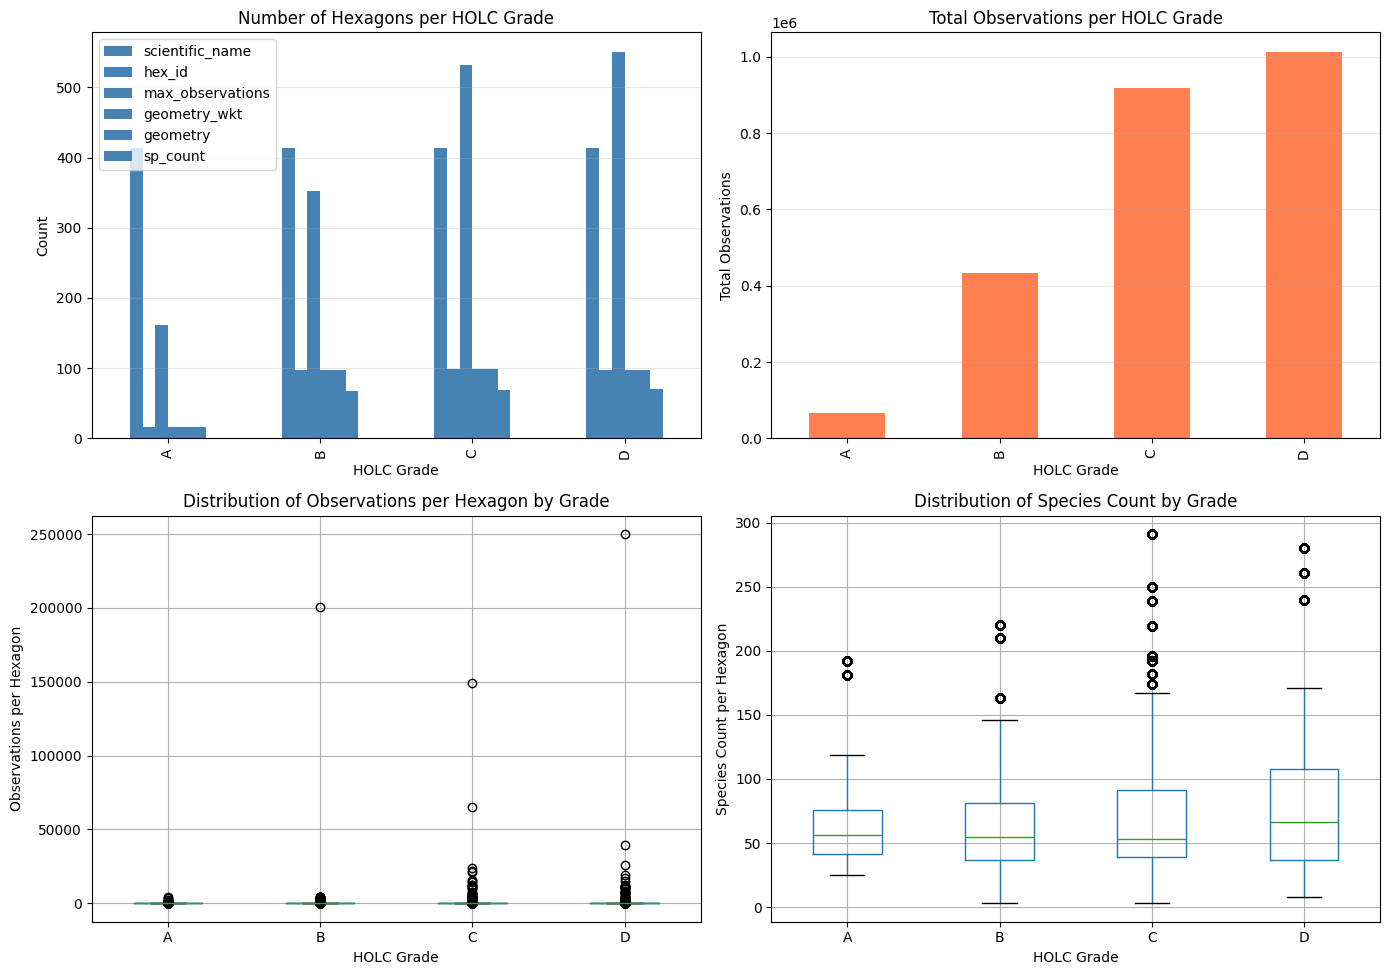

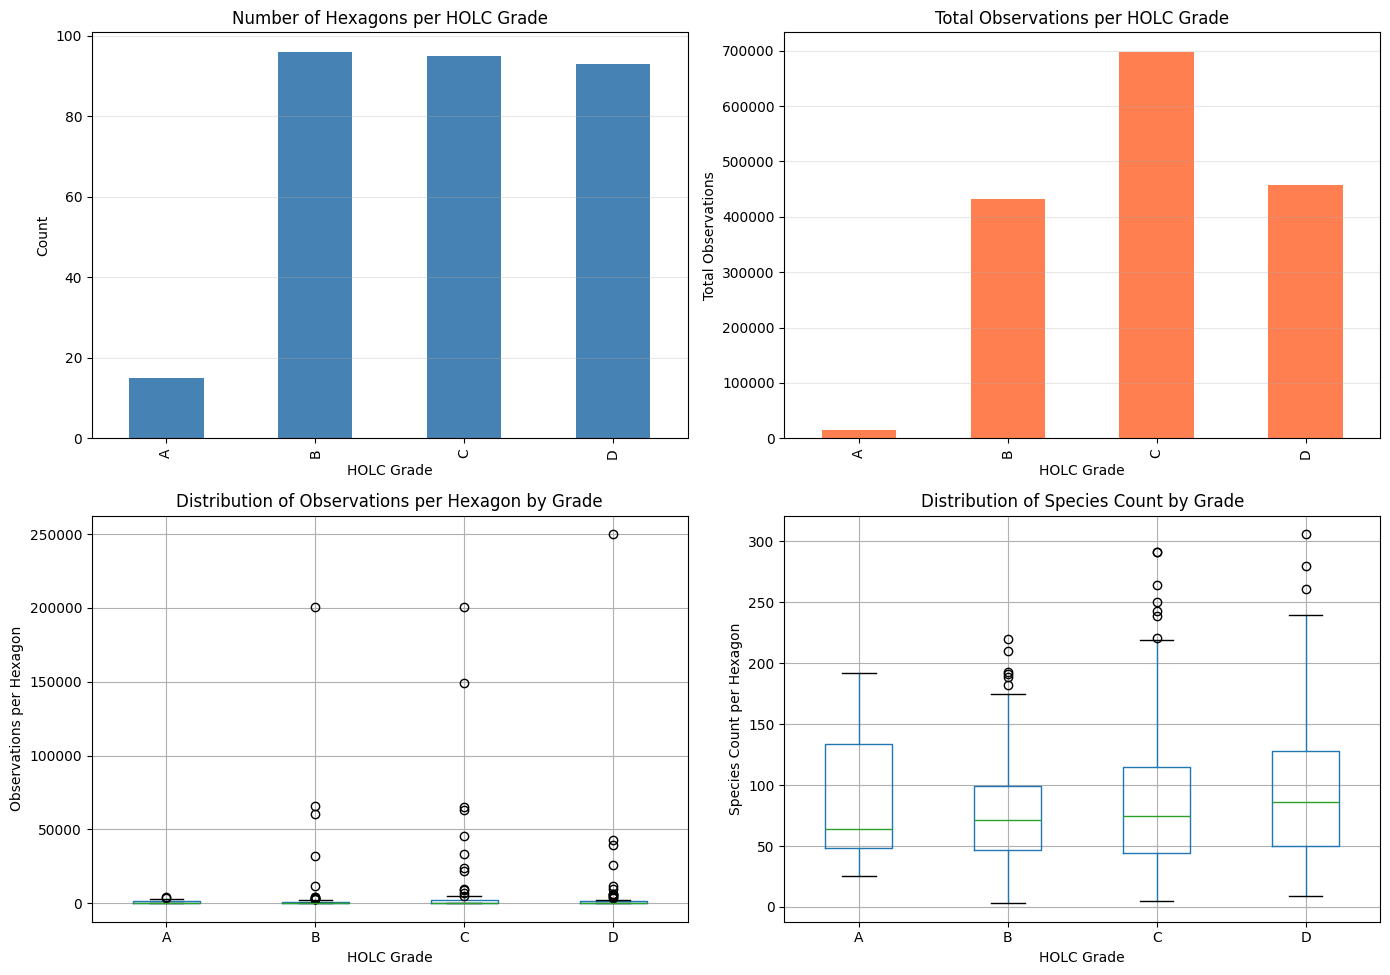

In [ ]:
""" import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Number of hexagons per grade
hex_count =ebird_filtered_final.groupby('grade').nunique('hex_id')
ax1 = axes[0, 0]
hex_count.plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Number of Hexagons per HOLC Grade')
ax1.set_xlabel('HOLC Grade')
ax1.set_ylabel('Count')
ax1.grid(axis='y', alpha=0.3)

# 2. Total observations per grade
ax2 = axes[0, 1]
obs_by_grade = ebird_filtered_final.groupby('grade')['max_observations'].sum()
obs_by_grade.plot(kind='bar', ax=ax2, color='coral')
ax2.set_title('Total Observations per HOLC Grade')
ax2.set_xlabel('HOLC Grade')
ax2.set_ylabel('Total Observations')
ax2.grid(axis='y', alpha=0.3)

# 3. Mean observations per hexagon by grade
ax3 = axes[1, 0]
ebird_filtered_final.boxplot(column='max_observations', by='grade', ax=ax3)
ax3.set_title('Distribution of Observations per Hexagon by Grade')
ax3.set_xlabel('HOLC Grade')
ax3.set_ylabel('Observations per Hexagon')
plt.suptitle('')  # Remove default title

# 4. Mean species count by grade
ax4 = axes[1, 1]
ebird_filtered_final.boxplot(column='sp_count', by='grade', ax=ax4)
ax4.set_title('Distribution of Species Count by Grade')
ax4.set_xlabel('HOLC Grade')
ax4.set_ylabel('Species Count per Hexagon')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show()




### 

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Number of hexagons per grade
grade_counts = selected_hexagons.groupby('grade').size()
ax1 = axes[0, 0]
grade_counts.plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Number of Hexagons per HOLC Grade')
ax1.set_xlabel('HOLC Grade')
ax1.set_ylabel('Count')
ax1.grid(axis='y', alpha=0.3)

# 2. Total observations per grade
ax2 = axes[0, 1]
obs_by_grade = selected_hexagons.groupby('grade')['max_observations'].sum()
obs_by_grade.plot(kind='bar', ax=ax2, color='coral')
ax2.set_title('Total Observations per HOLC Grade')
ax2.set_xlabel('HOLC Grade')
ax2.set_ylabel('Total Observations')
ax2.grid(axis='y', alpha=0.3)

# 3. Mean observations per hexagon by grade
ax3 = axes[1, 0]
selected_hexagons.boxplot(column='max_observations', by='grade', ax=ax3)
ax3.set_title('Distribution of Observations per Hexagon by Grade')
ax3.set_xlabel('HOLC Grade')
ax3.set_ylabel('Observations per Hexagon')
plt.suptitle('')  # Remove default title

# 4. Mean species count by grade
ax4 = axes[1, 1]
selected_hexagons.boxplot(column='sp_count', by='grade', ax=ax4)
ax4.set_title('Distribution of Species Count by Grade')
ax4.set_xlabel('HOLC Grade')
ax4.set_ylabel('Species Count per Hexagon')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show() """

In [ ]:


# Save outputs
selected_hexagons.to_file("../data/output/sfhex_100_post_spaced_4.18.26.geojson", driver='GeoJSON')



In [ ]:
#print out the first few rows of the GeoDataFrame to check the geometry column
ebird_HOLC_agg = selected_hexagons.copy()
print(ebird_HOLC_agg.head())
# Extract grade from hex_id (last character)
ebird_HOLC_agg= ebird_HOLC_agg.copy()
ebird_HOLC_agg['grade'] = ebird_HOLC_agg['hex_id'].str[-1]

# Export intermediate step
#output_path = "D:/Chapter1_LA_redlining/ebird_HOLC_agg.geojson"
#ebird_HOLC_agg.to_file(output_path)

print(f"Unique grades: {ebird_HOLC_agg['grade'].unique()}")
print(f"Rows after filtering: {len(ebird_HOLC_agg)}")



       scientific_name   hex_id  max_observations  \
16143   Ardenna grisea   3099_B          200403.0   
207648  Ardenna grisea  10582_D          250000.0   
8756    Ardenna grisea   7379_C          149313.0   
194230  Gavia stellata  12578_D           42939.0   
7892    Ardenna grisea   9049_C           63043.0   

                                             geometry_wkt grade  \
16143   POLYGON ((545496.1110660861 4178083.796200612,...     B   
207648  POLYGON ((551346.0988411442 4177131.148214674,...     D   
8756    POLYGON ((548846.1048163925 4176611.53587873, ...     C   
194230  POLYGON ((552896.0909269789 4179296.2084079287...     D   
7892    POLYGON ((550146.1011620308 4177650.7686153003...     C   

                                                 geometry  sp_count  \
16143   POLYGON ((545496.111 4178083.796, 545446.111 4...       220   
207648  POLYGON ((551346.099 4177131.148, 551296.099 4...       127   
8756    POLYGON ((548846.105 4176611.536, 548796.105 4...       2